# Detecção de fraudes em rastreadores veiculares

Trabalho de Conclusão de Curso — Bacharelado em Engenharia Eletrônica, CEFET/RJ
**Autor:** Gustavo Luiz Ribeiro da Cruz

Este notebook é autossuficiente: todo o código está aqui dentro. Não é preciso clonar repositório nem instalar nada no computador. Basta executar as células na ordem.

**Modelos comparados:** Regressão Logística, Rede Neural (MLP) e XGBoost.

## Sumário

| Seção | Conteúdo |
|---|---|
| 0 | Preparação do ambiente e pastas do Drive |
| 1 | Tratamento das planilhas de auditoria |
| 2 | Base de janelas de 60 minutos |
| 3 | Matriz de variáveis |
| 4 | Experimento A: generalização temporal |
| 5 | Experimento B: rastreadores nunca vistos |
| 6 | Decisão final por rastreador |
| 7 | Figuras para a monografia |
| 8 | Modelos finais |
| 9 | Tabela de métricas |
| 10 | Classificador de um arquivo de rastreador |
| 11 | Ranking de uma pasta |

## Dados de entrada

Coloque no Google Drive:

- Meu Drive/dados_brutos — planilhas de auditoria originais (*_auditoria.csv ou .xlsx)
- Meu Drive/dataset_tratado — destino dos arquivos tratados (*_treated.csv) e da pasta resultados/figuras

Se você já tem os arquivos *_treated.csv, desligue TRATAR_DADOS_BRUTOS na seção 0.

## 0. Preparação do ambiente

In [1]:
!pip -q install xgboost

import gc
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, auc, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive")
except Exception:
    RAIZ = Path.cwd()

DIR_BRUTOS = RAIZ / "dados_brutos"
DIR_TRATADOS = RAIZ / "dataset_tratado"
DIR_RESULT = DIR_TRATADOS / "resultados"
DIR_FIG = DIR_RESULT / "figuras"
DIR_TRATADOS.mkdir(parents=True, exist_ok=True)
DIR_FIG.mkdir(parents=True, exist_ok=True)

# formato de data das planilhas e casas decimais das coordenadas exportadas
DATE_FMT = "%d/%m/%Y %H:%M"    # ex.: 02/01/2024 00:19
COORD_DECIMALS = 7             # ex.: -129.051.470 -> -12.9051470

# opções de execução
TRATAR_DADOS_BRUTOS = True    # gera os *_treated.csv a partir de dados_brutos/
RECONSTRUIR_BASE = True       # refaz a base de janelas (False reaproveita o cache)
PRECISAO_MINIMA = 0.5         # precisão mínima exigida na escolha do limiar
PESO_ENERGIA = 3.0            # peso das variáveis de alimentação no XGBoost
N_REPETICOES = 1              # repetições da validação cruzada por grupos (1 = mais rápido)
SEED = 42

MODELOS = ["Regressão Logística", "Rede Neural (MLP)", "XGBoost"]
SIGLA = {"Regressão Logística": "rl", "Rede Neural (MLP)": "mlp", "XGBoost": "xgb"}
CORES = {"Regressão Logística": "#1f77b4", "Rede Neural (MLP)": "#2ca02c", "XGBoost": "#d62728"}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print("pastas:", DIR_BRUTOS, "|", DIR_TRATADOS)

Mounted at /content/drive
pastas: /content/drive/MyDrive/dados_brutos | /content/drive/MyDrive/dataset_tratado


## 1. Tratamento das planilhas de auditoria

As exportações trazem problemas que precisam ser corrigidos antes da análise: datas e durações como texto (que o one-hot-encoding descartaria, perdendo minuto e segundo), coordenadas com separador de milhar, acentuação corrompida, ';' dentro do endereço e cabeçalhos com nomes repetidos.

In [2]:
def corrigir_texto(s):
    """Corrige acentuação corrompida (ex.: 'NÃƒO' -> 'NÃO')."""
    if not isinstance(s, str):
        return s
    try:
        return s.encode("cp1252").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s


def para_datetime(serie):
    """Texto 'dd/mm/aaaa HH:MM[:SS]' ou datetime do Excel -> datetime64."""
    if pd.api.types.is_datetime64_any_dtype(serie):
        return serie
    s = serie.astype(str).str.strip()
    dt = pd.to_datetime(s, format=DATE_FMT, errors="coerce")
    faltando = dt.isna()
    if faltando.any():   # tenta com segundos / outros formatos
        dt[faltando] = pd.to_datetime(s[faltando], dayfirst=True, errors="coerce")
    return dt


def para_segundos(serie):
    """'HH:MM:SS' -> segundos (float). Aceita também timedelta/time do Excel."""
    s = serie.astype(str).str.strip()
    return pd.to_timedelta(s, errors="coerce").dt.total_seconds()


def corrigir_coordenada(valor, casas=COORD_DECIMALS):
    """
    A exportação gravou as coordenadas com pontos de milhar:
    '-129.051.470' -> -12.9051470  |  '-384.322.470' -> -38.4322470.
    Valores já numéricos e válidos (|x| <= 180) são mantidos. 0 vira NaN.
    """
    if pd.isna(valor):
        return np.nan
    if isinstance(valor, (int, float)) and abs(valor) <= 180 and float(valor).is_integer() is False:
        return float(valor) if valor != 0 else np.nan
    s = str(valor).strip().replace(",", ".")
    neg = s.startswith("-")
    digitos = "".join(ch for ch in s if ch.isdigit())
    if not digitos or int(digitos) == 0:
        return np.nan
    if s.count(".") == 1 and len(s.split(".")[1]) == casas:   # já está correto (ex.: -12.9051470)
        v = float(s)
    else:
        v = int(digitos) / 10 ** casas
    v = -v if neg else v
    return v if abs(v) <= 180 else np.nan


def sim_nao(serie):
    m = {"SIM": 1, "NÃO": 0, "NAO": 0, "TRUE": 1, "FALSE": 0, "1": 1, "0": 0}
    return serie.astype(str).str.strip().str.upper().map(m)


EVENTO_INICIO = "ENTERING GSM JAMMER AREA"
EVENTO_FIM    = "LEAVING GSM JAMMER AREA"

def rotular_fraude(df):
    estado = pd.Series(np.nan, index=df.index)
    estado[df["Reason Code"] == EVENTO_INICIO] = 1
    estado[df["Reason Code"] == EVENTO_FIM] = 1      # o próprio evento de saída ainda está no jammer
    # depois do evento de saída, volta a 0
    proximo_normal = (df["Reason Code"] == EVENTO_FIM).shift(fill_value=False)
    estado[proximo_normal & estado.isna()] = 0
    estado.iloc[0] = 0 if pd.isna(estado.iloc[0]) else estado.iloc[0]
    return estado.ffill().astype(int)


CATEGORICAS_ONEHOT = ["Reason Code", "HDOP STATUS"]
DESCARTAR = ["Place", "Plate", "Ibutton", "Creation date", "Reception date"]

LINHAS_CORRIGIDAS = {}   # arquivo -> nº de linhas com ";" extra

def ler_bruto(fp):
    """
    Lê a planilha de auditoria linha a linha.
    Linhas com mais campos que o cabeçalho (ex.: endereço em 'Place' contendo ';')
    têm o excedente reunido de volta na ÚLTIMA coluna, em vez de quebrar a leitura.
    Linhas com campos a menos são completadas com vazio.
    """
    if fp.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(fp, dtype=str)
    raw = fp.read_bytes()
    texto = None
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            texto = raw.decode(enc)
            break
        except UnicodeDecodeError:
            continue
    linhas = [l for l in texto.splitlines() if l.strip()]
    cab = [c.strip() for c in linhas[0].split(";")]
    n = len(cab)
    dados, corrigidas = [], 0
    for l in linhas[1:]:
        campos = l.split(";")
        if len(campos) > n:
            campos = campos[:n - 1] + [";".join(campos[n - 1:])]
            corrigidas += 1
        elif len(campos) < n:
            campos += [""] * (n - len(campos))
        dados.append(campos)
    LINHAS_CORRIGIDAS[fp.name] = corrigidas
    df = pd.DataFrame(dados, columns=cab, dtype=object)
    return df.replace({"": np.nan})


def limpar_texto(v):
    """Strip + correção de acentos, segura para NaN e valores não-texto."""
    if isinstance(v, str):
        v = corrigir_texto(v).strip()
        return v if v else np.nan
    return v


COLUNAS_DUPLICADAS = {}   # arquivo -> nomes repetidos no cabeçalho

def nomes_unicos(colunas, arquivo=""):
    """
    Alguns arquivos têm cabeçalho com nomes repetidos (ex.: duas colunas 'Lat'
    ou colunas vazias). Com nomes repetidos, df['col'] devolve um DataFrame
    em vez de uma Series. Aqui cada repetição recebe sufixo: Lat, Lat_2, ...
    Colunas sem nome viram 'sem_nome', 'sem_nome_2', ...
    """
    vistos, saida, repetidos = {}, [], []
    for c in colunas:
        c = str(c).strip() or "sem_nome"
        if c.startswith("Unnamed"):
            c = "sem_nome"
        if c in vistos:
            vistos[c] += 1
            repetidos.append(c)
            saida.append(f"{c}_{vistos[c]}")
        else:
            vistos[c] = 1
            saida.append(c)
    if repetidos:
        COLUNAS_DUPLICADAS[arquivo] = sorted(set(repetidos))
    return saida


def tratar_arquivo(fp):
    df = ler_bruto(fp).dropna(how="all")
    df.columns = nomes_unicos(df.columns, fp.name)
    # Remove colunas totalmente vazias e sem nome (sobras de ';' no fim do cabeçalho)
    df = df.drop(columns=[c for c in df.columns
                          if c.startswith("sem_nome") and df[c].isna().all()])
    for i in range(df.shape[1]):                      # por posição: nunca devolve DataFrame
        if df.iloc[:, i].dtype == object:
            df.iloc[:, i] = df.iloc[:, i].map(limpar_texto)
    if "Location date" not in df.columns:
        raise ValueError(f"coluna 'Location date' ausente. Colunas: {list(df.columns)}")

    # --- Tempo: mantém data + hora + minuto -------------------------
    df["timestamp"] = para_datetime(df["Location date"])
    df = df.dropna(subset=["timestamp"]).sort_values("timestamp", kind="stable")
    df = df.drop_duplicates().reset_index(drop=True)
    df["Data"]   = df["timestamp"].dt.strftime("%Y-%m-%d")
    df["Hora"]   = df["timestamp"].dt.hour
    df["Minuto"] = df["timestamp"].dt.minute
    df["hora_decimal"] = df["Hora"] + df["Minuto"] / 60
    df["hora_sin"] = np.sin(2 * np.pi * df["hora_decimal"] / 24)   # codificação cíclica
    df["hora_cos"] = np.cos(2 * np.pi * df["hora_decimal"] / 24)
    df["dia_semana"] = df["timestamp"].dt.dayofweek
    for c in ["Delay", "Reception delay"]:
        if c in df:
            df[c.replace(" ", "_") + "_seg"] = para_segundos(df[c])
    df = df.drop(columns=[c for c in ["Delay", "Reception delay", "Location date"] if c in df])

    # --- Numéricas ---------------------------------------------------
    for c in ["Speed", "GPS Satellites", "GSM Signal", "HDOP",
              "External Voltage", "Internal Battery", "Hodometer"]:
        if c in df:
            df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", "."), errors="coerce")
    df["Lat"] = df["Lat"].map(corrigir_coordenada)
    df["Lng"] = df["Lng"].map(corrigir_coordenada)

    # --- Binárias ----------------------------------------------------
    for c in ["Ignition", "Block Car"]:
        if c in df:
            df[c] = sim_nao(df[c])

    # --- Rótulo (antes do one-hot, usa o texto do Reason Code) -------
    df["Fraude"] = rotular_fraude(df)

    # --- One-hot só das categóricas reais ----------------------------
    prefixos = {"Reason Code": "motivo", "HDOP STATUS": "hdop_status"}
    cols_oh = [c for c in CATEGORICAS_ONEHOT if c in df]
    df = pd.get_dummies(df, columns=cols_oh, prefix=[prefixos[c] for c in cols_oh], dtype=int)

    rastreador = (str(df["Module Id"].dropna().iloc[0])
                  if "Module Id" in df and df["Module Id"].notna().any()
                  else fp.stem.replace("_auditoria", ""))
    df["rastreador"] = rastreador
    df = df.drop(columns=[c for c in DESCARTAR + ["Module Id"] if c in df])
    df["timestamp"] = df["timestamp"].dt.strftime("%Y-%m-%d %H:%M:%S")
    return df, rastreador

In [3]:
if TRATAR_DADOS_BRUTOS:
    arquivos_brutos = sorted([*DIR_BRUTOS.glob("*.csv"), *DIR_BRUTOS.glob("*.xlsx")])
    falhas = []
    for fp in arquivos_brutos:
        try:
            df_tratado, _ = tratar_arquivo(fp)
            destino = DIR_TRATADOS / f"{fp.stem.replace('_auditoria', '')}_treated.csv"
            df_tratado.to_csv(destino, sep=";", index=False, encoding="utf-8")
        except Exception as e:
            falhas.append((fp.name, f"{type(e).__name__}: {e}"))
    print(f"{len(arquivos_brutos) - len(falhas)} de {len(arquivos_brutos)} arquivos tratados")
    print(f"linhas com ';' extra reagrupadas: {sum(LINHAS_CORRIGIDAS.values())}")
    if COLUNAS_DUPLICADAS:
        print("cabeçalhos com nomes repetidos:", COLUNAS_DUPLICADAS)
    for nome_erro, erro in falhas:
        print(f"  {nome_erro}: {erro}")
else:
    print("tratamento desativado: usando os *_treated.csv existentes em", DIR_TRATADOS)

2 de 2 arquivos tratados
linhas com ';' extra reagrupadas: 0


## 2. Base de janelas de 60 minutos

Cada amostra é uma janela de 60 minutos de um único rastreador. As variáveis são calculadas dentro dele e comparam o rastreador com ele mesmo: tensão relativa à própria mediana, área habitual de circulação e duração das condições de sinal.

Rótulo de fraude: jammer com pelo menos 30 minutos e/ou violação de alimentação (energia externa cortada enquanto o veículo se move com a ignição desligada). Um arquivo de fraudes confirmadas em resultados/fraudes_confirmadas.csv, com as colunas rastreador, inicio e fim, substitui o rótulo automático.

In [4]:
# ═════════════ PARÂMETROS DE DOMÍNIO (ajustáveis) ═════════════
TARGET = "Fraude"
VAZAMENTO_PATTERNS = ["JAMMER"]      # colunas que definem o rótulo nunca viram feature

PARAMS = dict(
    JANELA_MIN=60,             # cada amostra do modelo = 1 janela de 60 min de um rastreador
    ROTULO_DURACAO_MIN=30,     # jammer só é FRAUDE se persistir >= 30 min (0 = rótulo antigo)
    DURACAO_MIN_SUSPEITA=30,   # persistência mínima das condições de sinal (min)
    DELAY_ALTO_SEG=600,        # atraso de recepção anormal (no exemplo, p90 normal ~ 400 s)
    HDOP_ALTO=3.0,
    SATELITES_MIN=4,
    GSM_FRACO_DBM=-105,        # no exemplo, dentro do jammer o GSM fica em -111 dBm
    GAP_TRANSMISSAO_MIN=45,    # parado, o rastreador transmite a cada ~30 min
    TENSAO_EXT_MIN=6.0,        # abaixo disso: alimentação externa cortada (V)
    PARADO_KMH=3,
    GRADE_GRAUS=0.01,          # célula de ~1 km para definir a "área habitual"
    FREQ_LOCAL_RARO=0.01,      # local onde o rastreador passa < 1% do tempo = incomum
    SALTO_KM=1.0,              # deslocamento após um apagão de transmissão
    KMH_MOVIMENTO=5,           # acima disso o veículo está andando
    # Violação de alimentação (assinatura do caso confirmado 69251992...):
    # tensão externa cortada + veículo andando com ignição DESLIGADA
    MIN_REG_MOV_SEM_IGN=3,     # nº mínimo de registros andando com ignição off e energia cortada
    # Rótulo: "jammer" | "energia" | "ambos"  (fraudes_confirmadas.csv tem prioridade)
    ROTULO_MODO="ambos",
)

# Famílias de Reason Code: cada firmware escreve o mesmo evento de um jeito
# (ex.: "ENTERING GSM JAMMER AREA" x "GMS JAMMING ACTIVATED").
FAMILIAS_EVENTO = {
    "evt_jammer_inicio": r"ENTERING.*JAMM|JAMMING ACTIVATED|JAMMER ON",
    "evt_jammer_fim":    r"LEAVING.*JAMM|JAMMING DISABLED|JAMMER OFF",
    # Lista "REASON CODES (FRAUDE)": CALAMP, CONCOX, MXT, NEWTEC, PV_MXT,
    # SERTEC_RST, ST3XX, ST4XX, QUECLINK (54 códigos, todos cobertos abaixo)
    "evt_falha_energia": (r"EXTERNAL POWER FAIL|(EXTERNAL|MAIN) POWER( SUPPLY)? DISCONNECT"
                          r"|DISCONNECTED WITH THE MAIN POWER|(^|_)POWER DISCONNECT|POWER SUPPLY DISCONNECTED"
                          r"|REMOVE MAIN POWER|EXTERNAL BATTERY REMOVED|POWER SUPPLY ERROR|MAIN POWER (LOST|OFF)"),
    "evt_energia_ok":    (r"EXTERNAL POWER OK|(EXTERNAL|MAIN) POWER( SUPPLY)? CONNECT"
                          r"|(?<!DIS)CONNECTED WITH THE MAIN POWER|(^|_)POWER CONNECT"
                          r"|EXTERNAL BATTERY CONNECTED|POWER RECONNECT|MAIN POWER (ON|OK)"),
    "evt_tensao_baixa":  (r"LOW BATTERY|BATTERY LOW|LOW BACKUP BATTERY|BATTERY VOLTAGE BELOW"
                          r"|BELOW PWR THRES|DUE TO LOW POWER|BATTERY ERROR"),
    "evt_bateria_backup_removida": (r"BACKUP BATTERY UNPLUGGED|INTERNAL BATTERY REMOVED"
                                    r"|DISCONNECTED WITH THE BACK-?UP BATTERY|(^|_)BATTERY DISCONNECT"),
    "evt_bateria_backup_ok": (r"BACKUP BATTERY PLUGGED|INTERNAL BATTERY CONNECTED"
                              r"|(?<!DIS)CONNECTED WITH THE BACK-?UP BATTERY|(^|_)BATTERY CONNECT"),
    "evt_antena_gps_removida": r"GPS ANTENNA (UNPLUGGED|DISCONNECT)|(^|_)DISCONNECTED GPS ANTENNA|GPS SIGNAL FAILURE",
    "evt_antena_gps_ok": r"GPS ANTENNA (PLUGGED|CONNECT)|RECONNECTED GPS ANTENNA",
    "evt_desligamento":  r"POWER OFF|SHUT ?DOWN|(^|_)DISCONNECT$",
    "evt_religamento":   r"POWER ON|WAKE UP|GPRS FIRST ATTACHED|REBOOT|RESTART",
    "evt_seguranca":     r"UNAUTHORIZED DRIVER|PASSWORD WRONG|SUSPICIOUS|TRUCK (DIS)?CONNECTED",
    "evt_reconstrucao":  r"RECONSTRUCTION|STORED|BUFFER|OFFLINE",
}

# Famílias que, sozinhas, já indicam adulteração física do equipamento
EVENTOS_CRITICOS = ["evt_falha_energia", "evt_bateria_backup_removida",
                    "evt_antena_gps_removida", "evt_seguranca"]


def relatorio_cobertura(colunas_motivo):
    """Mostra quais Reason Codes da base caem em cada família e quais ficaram de fora."""
    linhas = []
    for c in colunas_motivo:
        fams = [f for f, p in FAMILIAS_EVENTO.items() if re.search(p, c.upper())]
        linhas.append({"reason_code": c.replace("motivo_", ""), "familias": ", ".join(fams) or "-"})
    return pd.DataFrame(linhas)


def familias_evento(df):
    """Soma as colunas one-hot de Reason Code em famílias comparáveis entre firmwares."""
    motivos = [c for c in df.columns if c.startswith("motivo_")]
    out = {}
    for fam, padrao in FAMILIAS_EVENTO.items():
        cols = [c for c in motivos if re.search(padrao, c.upper())]
        out[fam] = (df[cols].apply(pd.to_numeric, errors="coerce").fillna(0).sum(axis=1)
                    if cols else pd.Series(0, index=df.index)).astype("int16")
    return pd.DataFrame(out, index=df.index)


def gsm_em_dbm(gsm):
    """Alguns firmwares mandam GSM em dBm (-113 a -51), outros em CSQ (0 a 31; 99 = desconhecido)."""
    g = gsm.where(gsm != 99)
    if (g.dropna() >= 0).mean() > 0.8:          # escala CSQ
        return -113 + 2 * g.clip(0, 31)
    return g


def _num(df, c):
    if c in df.columns:
        return pd.to_numeric(df[c], errors="coerce")
    return pd.Series(np.nan, index=df.index, dtype="float64")


def haversine_vec(lat1, lon1, lat2, lon2, R=6371.0):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))


def duracao_continua(cond, ts):
    """Minutos desde o início da sequência ininterrupta em que cond é verdadeira."""
    cond = pd.Series(cond, index=ts.index).fillna(False).astype(bool)
    run = (cond != cond.shift()).cumsum()
    inicio = ts.groupby(run).transform("min")
    return ((ts - inicio).dt.total_seconds() / 60).where(cond, 0.0).astype("float32")


def rotulo_persistente(fraude, ts, dur_min):
    """Fraude = estado de jammer que dura pelo menos dur_min minutos."""
    fr = fraude.fillna(0).astype(int)
    run = (fr != fr.shift()).cumsum()
    fim = ts.shift(-1).fillna(ts)
    ini = ts.groupby(run).transform("min")
    fim_run = fim.groupby(run).transform("max")
    dur = ((fim_run - ini).dt.total_seconds() / 60).where(fr == 1)
    inicio_ep = (fr == 1) & (fr.shift(fill_value=0) != 1)
    return ((fr == 1) & (dur >= dur_min)).astype("int8"), dur, inicio_ep


def features_registro(df, P=PARAMS):
    """Features por registro, calculadas DENTRO de um único rastreador, em ordem temporal."""
    df = df.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    df = df.dropna(subset=["timestamp"]).sort_values("timestamp", kind="stable").reset_index(drop=True)
    ts = df["timestamp"]
    D = P["DURACAO_MIN_SUSPEITA"]
    delay, hdop, sat = _num(df, "Reception_delay_seg"), _num(df, "HDOP"), _num(df, "GPS Satellites")
    gsm, vext, bat = _num(df, "GSM Signal"), _num(df, "External Voltage"), _num(df, "Internal Battery")
    lat, lng, vel, ign = _num(df, "Lat"), _num(df, "Lng"), _num(df, "Speed"), _num(df, "Ignition")
    lat, lng = lat.where(lat != 0), lng.where(lng != 0)
    gsm = gsm_em_dbm(gsm)
    if bat.fillna(0).eq(0).all():               # rastreador sem bateria interna medida
        bat = pd.Series(np.nan, index=df.index)
    if sat.max() > 24:                          # alguns firmwares somam satélites visíveis de várias constelações
        sat = sat.where(sat > 0)
    fam = familias_evento(df)

    out = pd.DataFrame({"timestamp": ts})
    dt_min = ts.diff().dt.total_seconds() / 60
    out["dt_min"] = dt_min

    # Sinal: só a DURAÇÃO conta (um pico curto = interferência comum, não fraude)
    out["delay_alto"] = (delay > P["DELAY_ALTO_SEG"]).astype("int8")
    out["dur_delay_alto"] = duracao_continua(delay > P["DELAY_ALTO_SEG"], ts)
    out["dur_hdop_alto"] = duracao_continua(hdop >= P["HDOP_ALTO"], ts)
    out["dur_sem_gps"] = duracao_continua(sat < P["SATELITES_MIN"], ts)
    out["dur_gsm_fraco"] = duracao_continua(gsm <= P["GSM_FRACO_DBM"], ts)

    # Energia: tensão externa e bateria interna, relativas ao próprio rastreador
    # Estado da alimentação pelos EVENTOS (falha -> cortada, ok -> normal).
    # Usado quando o firmware não envia tensão externa naquele registro.
    est = pd.Series(np.nan, index=df.index)
    est[fam["evt_falha_energia"] > 0] = 1
    est[fam["evt_energia_ok"] > 0] = 0
    est.iloc[0] = 0 if pd.isna(est.iloc[0]) else est.iloc[0]
    est = est.ffill()
    # o estado por evento expira em 12 h sem confirmação (evita "corte eterno" se faltar o evento de volta)
    ult_evt = ts.where((fam["evt_falha_energia"] > 0) | (fam["evt_energia_ok"] > 0)).ffill()
    est = est.where((ts - ult_evt) <= pd.Timedelta(hours=12), 0)
    ext_cortada = (vext < P["TENSAO_EXT_MIN"]).where(vext.notna(), est == 1).astype(bool)
    out["ext_cortada"] = ext_cortada.astype("int8")
    out["dur_ext_cortada"] = duracao_continua(ext_cortada, ts)
    out["vext"] = vext
    out["tensao_rel"] = vext - vext.median()
    out["queda_tensao"] = (-vext.diff()).clip(lower=0)
    out["bat"] = bat
    out["bateria_rel"] = bat - bat.median()
    out["queda_bateria"] = (-bat.diff()).clip(lower=0)

    # Posição: deslocamento, salto após apagão e área habitual do próprio rastreador
    d = haversine_vec(lat.shift(), lng.shift(), lat, lng)
    out["dist_km"] = d
    out["salto_pos_gap_km"] = np.where(dt_min > P["GAP_TRANSMISSAO_MIN"], d, 0.0)
    g = P["GRADE_GRAUS"]
    ok = lat.notna() & lng.notna()
    celula = pd.Series("", index=df.index)
    celula[ok] = ((lat[ok] / g).round().astype(int).astype(str) + "_"
                  + (lng[ok] / g).round().astype(int).astype(str))
    out["freq_local"] = celula.map(celula[ok].value_counts(normalize=True)).where(ok).astype("float32")
    out["dist_mediana_km"] = haversine_vec(lat, lng, lat.median(), lng.median())
    out["parado"] = (vel < P["PARADO_KMH"]).astype("int8")
    out["speed"], out["ignicao"] = vel, ign
    out["hora_sin"], out["hora_cos"] = _num(df, "hora_sin"), _num(df, "hora_cos")

    # Regras do especialista (a sua forma de reconhecer fraude)
    degradado = pd.concat([out["dur_delay_alto"], out["dur_hdop_alto"],
                           out["dur_gsm_fraco"], out["dur_sem_gps"]], axis=1).max(axis=1)
    local_suspeito = (out["freq_local"] < P["FREQ_LOCAL_RARO"]) | (out["salto_pos_gap_km"] > P["SALTO_KM"])
    out["sinal_degradado_persistente"] = (degradado >= D).astype("int8")
    out["regra_combinada"] = ((degradado >= D) & local_suspeito).astype("int8")
    out["regra_energia"] = (out["dur_ext_cortada"] >= D).astype("int8")

    # Violação de alimentação: energia externa cortada E veículo andando com ignição desligada.
    # Fisicamente incoerente: o carro roda 100 km/h "desligado" enquanto o rastreador
    # está na bateria de backup e só depois envia a rota (ROUTE'S RECONSTRUCTION).
    andando = vel > P["KMH_MOVIMENTO"]
    out["mov_sem_ignicao"] = (andando & (ign == 0)).astype("int8")
    out["mov_sem_ign_cortada"] = (andando & (ign == 0) & ext_cortada).astype("int8")
    for c in fam.columns:
        if not c.startswith("evt_jammer"):
            out[c] = fam[c].values

    # Episódios contínuos de energia cortada
    run_ext = (ext_cortada != ext_cortada.shift()).cumsum()
    n_mov_ep = out["mov_sem_ign_cortada"].groupby(run_ext).transform("sum")
    dur_ep_ext = out["dur_ext_cortada"].groupby(run_ext).transform("max")
    violacao = ext_cortada & ((n_mov_ep >= P["MIN_REG_MOV_SEM_IGN"]) | (dur_ep_ext >= D))
    out["regra_violacao_energia"] = violacao.astype("int8")

    # Adulteração física: antena GPS ou bateria de backup removida, evento de segurança,
    # ou falha de energia — só vira alarme se houver CONFIRMAÇÃO no comportamento
    # (energia cortada ou veículo andando com ignição desligada nas 2 h seguintes).
    critico = fam[[c for c in EVENTOS_CRITICOS if c in fam]].sum(axis=1) > 0
    confirma = (ext_cortada | (out["mov_sem_ignicao"] == 1)).astype(int)
    # olha 2 h para a frente: para cada registro, existe confirmação em [t, t + 2 h]?
    # (ts já está em ordem crescente; soma acumulada + busca binária)
    t_ns = ts.to_numpy("datetime64[ns]")
    fim = np.searchsorted(t_ns, t_ns + np.timedelta64(2, "h"), side="right")
    acum = np.concatenate([[0], np.cumsum(confirma.to_numpy())])
    confirma_2h = acum[fim] - acum[np.arange(len(t_ns))]
    out["regra_adulteracao"] = (critico & (confirma_2h > 0)).astype("int8")

    for c in df.columns:   # contagem de eventos brutos (sem os que definem o rótulo de jammer)
        if c.startswith("motivo_") and not re.search("JAMM", c.upper()):
            out["n_" + c] = pd.to_numeric(df[c], errors="coerce").fillna(0).astype("int8")

    # Rótulo de jammer recalculado aqui a partir das famílias (vale para todos os firmwares)
    estado = pd.Series(np.nan, index=df.index)
    estado[fam["evt_jammer_inicio"] > 0] = 1
    estado[fam["evt_jammer_fim"] > 0] = 0
    estado.iloc[0] = 0 if pd.isna(estado.iloc[0]) else estado.iloc[0]
    jam_estado = estado.ffill().astype(int)
    jam_estado[fam["evt_jammer_fim"] > 0] = 1       # o registro de saída ainda está no jammer
    rot_jam, out["_dur_jammer"], out["_ini_jammer"] = rotulo_persistente(
        jam_estado, ts, P["ROTULO_DURACAO_MIN"])

    modo = P.get("ROTULO_MODO", "ambos")
    rot_en = out["regra_violacao_energia"]
    out[TARGET] = {"jammer": rot_jam, "energia": rot_en}.get(
        modo, ((rot_jam == 1) | (rot_en == 1)).astype("int8"))
    out["_rot_jammer"], out["_rot_energia"] = rot_jam, rot_en
    out["rastreador"] = str(df["rastreador"].iloc[0]) if "rastreador" in df.columns else "desconhecido"
    out["lat"], out["lng"] = lat, lng
    return out


def agregar_janelas(r, P=PARAMS):
    """Resume os registros em janelas de P['JANELA_MIN'] minutos: 1 linha = 1 janela."""
    r = r.copy()
    r["janela"] = r["timestamp"].dt.floor(f"{P['JANELA_MIN']}min")
    g = r.groupby("janela")
    J = pd.DataFrame({
        "n_registros": g.size(),
        "maior_gap_min": g["dt_min"].max(),
        "frac_delay_alto": g["delay_alto"].mean(),
        "dur_max_delay_alto": g["dur_delay_alto"].max(),
        "dur_max_hdop_alto": g["dur_hdop_alto"].max(),
        "dur_max_sem_gps": g["dur_sem_gps"].max(),
        "dur_max_gsm_fraco": g["dur_gsm_fraco"].max(),
        "frac_ext_cortada": g["ext_cortada"].mean(),
        "dur_max_ext_cortada": g["dur_ext_cortada"].max(),
        "tensao_rel_min": g["tensao_rel"].min(),
        "tensao_rel_media": g["tensao_rel"].mean(),
        "tensao_std": g["vext"].std(),
        "queda_tensao_max": g["queda_tensao"].max(),
        "bateria_rel_min": g["bateria_rel"].min(),
        "bateria_std": g["bat"].std(),
        "queda_bateria_max": g["queda_bateria"].max(),
        "dist_total_km": g["dist_km"].sum(),
        "salto_max_km": g["salto_pos_gap_km"].max(),
        "freq_local_min": g["freq_local"].min(),
        "dist_mediana_max_km": g["dist_mediana_km"].max(),
        "frac_parado": g["parado"].mean(),
        "frac_ignicao": g["ignicao"].mean(),
        "vel_media": g["speed"].mean(),
        "vel_max": g["speed"].max(),
        "hora_sin": g["hora_sin"].mean(),
        "hora_cos": g["hora_cos"].mean(),
        "sinal_degradado_persistente": g["sinal_degradado_persistente"].max(),
        "regra_combinada": g["regra_combinada"].max(),
        "regra_energia": g["regra_energia"].max(),
        "regra_violacao_energia": g["regra_violacao_energia"].max(),
        "n_mov_sem_ignicao": g["mov_sem_ignicao"].sum(),
        "n_mov_sem_ign_cortada": g["mov_sem_ign_cortada"].sum(),
        "n_evt_falha_energia": g["evt_falha_energia"].sum(),
        "n_evt_energia_ok": g["evt_energia_ok"].sum(),
        "n_evt_desligamento": g["evt_desligamento"].sum(),
        "n_evt_religamento": g["evt_religamento"].sum(),
        "n_evt_reconstrucao": g["evt_reconstrucao"].sum(),
        "n_evt_tensao_baixa": g["evt_tensao_baixa"].sum(),
        "n_evt_bateria_backup_removida": g["evt_bateria_backup_removida"].sum(),
        "n_evt_bateria_backup_ok": g["evt_bateria_backup_ok"].sum(),
        "n_evt_antena_gps_removida": g["evt_antena_gps_removida"].sum(),
        "n_evt_antena_gps_ok": g["evt_antena_gps_ok"].sum(),
        "n_evt_seguranca": g["evt_seguranca"].sum(),
        "regra_adulteracao": g["regra_adulteracao"].max(),
        "_rot_jammer": g["_rot_jammer"].max(),
        "_rot_energia": g["_rot_energia"].max(),
        "lat": g["lat"].median(),
        "lng": g["lng"].median(),
        TARGET: g[TARGET].max(),
        "_dur_jammer_max": g["_dur_jammer"].max(),
    })
    n_cols = [c for c in r.columns if c.startswith("n_motivo_")]
    if n_cols:
        J = J.join(g[n_cols].sum())
    J["n_registros_rel"] = J["n_registros"] / J["n_registros"].median()
    J = J.reset_index().rename(columns={"janela": "inicio_janela"})
    J["rastreador"] = r["rastreador"].iloc[0]
    return J


NAO_FEATURES = {"inicio_janela", "rastreador", "arquivo", "lat", "lng", TARGET}

# Features que DEFINEM o rótulo de energia: ficam fora do modelo de ML
# (senão ele só reaprende a regra). Elas continuam sendo usadas na CAMADA DE REGRAS.
DEFINEM_ROTULO_ENERGIA = {"regra_violacao_energia", "n_mov_sem_ign_cortada"}

def lista_features(J, P=PARAMS):
    excl = set(NAO_FEATURES)
    if P.get("ROTULO_MODO", "ambos") in ("energia", "ambos"):
        excl |= DEFINEM_ROTULO_ENERGIA
    return [c for c in J.columns
            if c not in excl and not c.startswith("_")
            and not any(p in c.upper() for p in VAZAMENTO_PATTERNS)]


# ═════════════ DECISÃO COMBINADA (veredito final do arquivo) ═════════════
# Cada indício isolado NUNCA basta para declarar fraude. Um episódio só é fraude se
# reunir pelo menos MIN_EVIDENCIAS categorias diferentes de indício E a confiança
# combinada (modelo + indícios) atingir RISCO_MIN.
DECISAO = dict(
    RISCO_MIN=0.50,              # confiança mínima para declarar FRAUDE
    MIN_EVIDENCIAS=2,            # nº mínimo de categorias diferentes no mesmo episódio
    TOLERANCIA_JANELAS=1,        # janelas sem indício permitidas dentro de um episódio
    GAP_APAGAO_MIN=180,          # apagão de transmissão (min)
    # peso dos indícios combinados (nº de categorias -> probabilidade "de regra")
    PESO_EVIDENCIAS={2: 0.30, 3: 0.45, 4: 0.80},   # 2–3 indícios precisam do modelo; 4+ bastam
    # os indícios precisam ocorrer JUNTOS: na mesma janela ou nas vizinhas (±1 janela).
    # Indícios espalhados em dias diferentes NÃO se somam.
)

NOMES_EVIDENCIA = {
    "ev_energia": "energia externa cortada / falha ou tensão baixa",
    "ev_movimento_incoerente": "veículo andando com ignição desligada",
    "ev_desligamento": "equipamento desligado / religado",
    "ev_adulteracao": "antena GPS ou bateria de backup removida / evento de segurança",
    "ev_sinal_persistente": "sinal degradado por 30 min ou mais",
    "ev_jammer_persistente": "jammer por 30 min ou mais",
    "ev_posicao": "local incomum ou salto de posição após apagão",
    "ev_apagao": "apagão longo de transmissão",
}


def _col(J, c, padrao=0):
    return J[c].fillna(padrao) if c in J.columns else pd.Series(padrao, index=J.index)


def evidencias_janela(J, P=PARAMS, D=DECISAO):
    """Uma coluna booleana por CATEGORIA de indício, para cada janela."""
    return pd.DataFrame({
        # >= 2 leituras de tensão cortada: 1 leitura zerada isolada costuma ser falha de leitura
        "ev_energia": (_col(J, "frac_ext_cortada") * _col(J, "n_registros") >= 2)
                      | (_col(J, "n_evt_falha_energia") > 0)
                      | (_col(J, "n_evt_tensao_baixa") > 0),
        "ev_movimento_incoerente": _col(J, "n_mov_sem_ignicao") >= P["MIN_REG_MOV_SEM_IGN"],
        "ev_desligamento": (_col(J, "n_evt_desligamento") > 0) | (_col(J, "n_evt_religamento") > 0),
        "ev_adulteracao": (_col(J, "n_evt_antena_gps_removida") + _col(J, "n_evt_bateria_backup_removida")
                           + _col(J, "n_evt_seguranca")) > 0,
        # parado na garagem sem GPS é normal: sinal só conta com o veículo em movimento
        "ev_sinal_persistente": (_col(J, "sinal_degradado_persistente") > 0)
                                & (_col(J, "vel_max") > P["KMH_MOVIMENTO"]),
        "ev_jammer_persistente": _col(J, "_rot_jammer") > 0,
        "ev_posicao": (_col(J, "freq_local_min", 1.0) < P["FREQ_LOCAL_RARO"])
                      | (_col(J, "salto_max_km") > P["SALTO_KM"]),
        "ev_apagao": _col(J, "maior_gap_min") > D["GAP_APAGAO_MIN"],
    }, index=J.index)


def decisao_combinada(J, prob, P=PARAMS, D=DECISAO):
    """
    Agrupa janelas com indícios em episódios e decide cada episódio.
    confiança = 1 - (1 - p_modelo) * (1 - p_indicios)   se n_categorias >= MIN_EVIDENCIAS
              = no máximo RISCO_MIN - 1%                 se houver só 1 categoria (nunca é fraude)
    Retorna (veredito, confiança_fraude, tabela_de_episódios, evidências por janela).
    """
    J = J.reset_index(drop=True)
    prob = np.nan_to_num(np.asarray(prob, dtype=float))
    ev = evidencias_janela(J, P, D)
    tem = ev.any(axis=1).to_numpy()
    passo = pd.Timedelta(minutes=P["JANELA_MIN"])
    episodio = np.full(len(J), -1)
    idx = np.where(tem)[0]
    if len(idx):
        t = J["inicio_janela"].iloc[idx]
        episodio[idx] = (t.diff() > passo * (1 + D["TOLERANCIA_JANELAS"])).cumsum().to_numpy()
    # co-ocorrência local: categorias da janela + vizinhas imediatas
    t_all = J["inicio_janela"]
    ant_ok = ((t_all - t_all.shift(1)) == passo).to_numpy()
    prox_ok = ((t_all.shift(-1) - t_all) == passo).to_numpy()
    E = ev.to_numpy(dtype=bool)
    loc = E.copy()
    loc[1:] |= E[:-1] & ant_ok[1:, None]
    loc[:-1] |= E[1:] & prox_ok[:-1, None]
    n_loc = loc.sum(axis=1)
    teto = D["RISCO_MIN"] - 0.01
    linhas = []
    for e in np.unique(episodio[episodio >= 0]):
        m = episodio == e
        i_best = np.where(m)[0][np.argmax(n_loc[m])]
        cats = [c for j, c in enumerate(ev.columns) if loc[i_best, j]]
        n = len(cats)
        p_mod = float(prob[m].max())
        p_ind = D["PESO_EVIDENCIAS"].get(min(n, max(D["PESO_EVIDENCIAS"])), 0.0) if n >= 2 else 0.0
        conf = 1 - (1 - p_mod) * (1 - p_ind) if n >= D["MIN_EVIDENCIAS"] else min(p_mod, teto)
        ini = J.loc[m, "inicio_janela"].min()
        fim = J.loc[m, "inicio_janela"].max() + passo
        linhas.append(dict(inicio=ini, fim=fim, duracao_h=(fim - ini).total_seconds() / 3600,
                           n_indicios=n, indicios="; ".join(NOMES_EVIDENCIA[c] for c in cats),
                           prob_modelo=round(p_mod, 3), confianca=round(conf, 3),
                           fraude=conf >= D["RISCO_MIN"],
                           lat=J.loc[m, "lat"].median(), lng=J.loc[m, "lng"].median()))
    ep = pd.DataFrame(linhas, columns=["inicio", "fim", "duracao_h", "n_indicios", "indicios",
                                       "prob_modelo", "confianca", "fraude", "lat", "lng"])
    if len(ep):
        conf_arquivo = float(ep["confianca"].max())
    else:
        conf_arquivo = float(min(prob.max() if len(prob) else 0.0, teto))
    veredito = "FRAUDE" if conf_arquivo >= D["RISCO_MIN"] else "NÃO FRAUDE"
    ep = ep.sort_values("confianca", ascending=False).reset_index(drop=True)
    return veredito, conf_arquivo, ep, ev

In [5]:
def montar_base(arquivos):
    blocos, duracoes = [], []
    for k, fp in enumerate(arquivos, 1):
        try:
            df = pd.read_csv(fp, sep=";", low_memory=False)
            if "timestamp" not in df.columns:
                print(f"{fp.name}: sem coluna timestamp, ignorado")
                continue
            reg = features_registro(df, PARAMS)
            duracoes += reg.loc[reg["_ini_jammer"].astype(bool), "_dur_jammer"].dropna().tolist()
            jan = agregar_janelas(reg, PARAMS)
        except Exception as e:
            print(f"{fp.name}: {type(e).__name__}: {e}")
            continue
        jan["arquivo"] = fp.stem.replace("_treated", "")
        blocos.append(jan)
        del df, reg
        gc.collect()
        if k % 20 == 0:
            print(f"{k}/{len(arquivos)} arquivos processados")
    base = pd.concat(blocos, ignore_index=True)
    contagens = [c for c in base.columns if c.startswith("n_motivo_")]
    base[contagens] = base[contagens].fillna(0)
    return base, duracoes


def aplicar_fraudes_confirmadas(base, caminho):
    conf = pd.read_csv(caminho, sep=";", dtype={"rastreador": str})
    conf["inicio"] = pd.to_datetime(conf["inicio"], dayfirst=True)
    conf["fim"] = pd.to_datetime(conf["fim"], dayfirst=True)
    fim_janela = base["inicio_janela"] + pd.Timedelta(minutes=PARAMS["JANELA_MIN"])
    rastreador = base["rastreador"].astype(str)
    arquivo = base["arquivo"].astype(str)
    rotulo = np.zeros(len(base), dtype="int8")
    for _, c in conf.iterrows():
        mesmo = (rastreador == c["rastreador"]) | (arquivo == c["rastreador"])
        sobrepoe = (base["inicio_janela"] < c["fim"]) & (fim_janela > c["inicio"])
        rotulo[(mesmo & sobrepoe).to_numpy()] = 1
    base[TARGET] = rotulo
    return len(conf)


cache = DIR_RESULT / "base_janelas.pkl"
if cache.exists() and not RECONSTRUIR_BASE:
    base, dur_jammer = pd.read_pickle(cache)
else:
    base, dur_jammer = montar_base(sorted(DIR_TRATADOS.glob("*_treated.csv")))
    pd.to_pickle((base, dur_jammer), cache)

confirmadas = DIR_RESULT / "fraudes_confirmadas.csv"
if confirmadas.exists():
    print("rótulo: períodos confirmados no arquivo:", aplicar_fraudes_confirmadas(base, confirmadas))
else:
    print(f"rótulo automático ({PARAMS['ROTULO_MODO']}): "
          f"{int(base['_rot_jammer'].sum())} janelas com jammer persistente, "
          f"{int(base['_rot_energia'].sum())} com violação de alimentação")

por_rastreador = base.groupby("rastreador")[TARGET].max()
print(f"{len(base)} janelas | {base['rastreador'].nunique()} rastreadores | "
      f"{int(base[TARGET].sum())} janelas com fraude ({base[TARGET].mean():.2%}) | "
      f"{int(por_rastreador.sum())} rastreadores com fraude")

dur = pd.Series(dur_jammer, dtype=float)
if len(dur):
    print("\nduração dos episódios de jammer (min):")
    for limite in [5, 15, 30, 60, 120]:
        print(f"  >= {limite:3d} min: {(dur >= limite).sum()}")

20/100 arquivos processados
40/100 arquivos processados
60/100 arquivos processados
80/100 arquivos processados
100/100 arquivos processados
rótulo automático (ambos): 7510 janelas com jammer persistente, 11225 com violação de alimentação
300615 janelas | 95 rastreadores | 18637 janelas com fraude (6.20%) | 66 rastreadores com fraude

duração dos episódios de jammer (min):
  >=   5 min: 3407
  >=  15 min: 2653
  >=  30 min: 2445
  >=  60 min: 643
  >= 120 min: 323


## 3. Matriz de variáveis

In [6]:
FEATURES = [c for c in base.columns
            if c not in NAO_FEATURES and not c.startswith("_")
            and not any(p in c.upper() for p in VAZAMENTO_PATTERNS)]
X = base[FEATURES].to_numpy(dtype=np.float32)
X[~np.isfinite(X)] = np.nan
y = base[TARGET].to_numpy(dtype=np.int8)
grupos = base["rastreador"].astype(str).to_numpy()
ts = base["inicio_janela"].to_numpy("datetime64[ns]")
print(f"X: {X.shape[0]} janelas x {X.shape[1]} variáveis")

TERMOS_ENERGIA = ("tensao", "ext_cortada", "bateria", "regra_energia")
CRESCENTES = ("dur_max_", "frac_ext", "queda_", "salto_", "maior_gap", "regra_", "sinal_degradado")
PESOS = np.array([PESO_ENERGIA if any(t in f for t in TERMOS_ENERGIA) else 1.0 for f in FEATURES])
MONOTONAS = tuple(1 if f.startswith(CRESCENTES) else (-1 if f == "freq_local_min" else 0)
                  for f in FEATURES)

X: 300615 janelas x 148 variáveis


### Definição e treino dos modelos

Imputação e padronização ficam dentro do Pipeline, ajustado somente no conjunto de treino, o que evita vazamento de dados. As variáveis de alimentação recebem peso maior no XGBoost e as variáveis de duração, queda, salto e regra têm restrição monotônica.

In [7]:
def criar_modelo(nome, y_treino):
    imputador = SimpleImputer(strategy="median", keep_empty_features=True)
    if nome == "Regressão Logística":
        return Pipeline([("imp", imputador), ("sc", StandardScaler()),
                         ("clf", LogisticRegression(class_weight="balanced", C=0.5,
                                                    max_iter=3000, random_state=SEED))])
    if nome == "Rede Neural (MLP)":
        return Pipeline([("imp", imputador), ("sc", StandardScaler()),
                         ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                               batch_size=256, learning_rate_init=1e-3,
                                               early_stopping=True, validation_fraction=0.15,
                                               n_iter_no_change=10, max_iter=150,
                                               random_state=SEED))])
    if nome == "XGBoost":
        negativos = int((y_treino == 0).sum())
        positivos = max(int((y_treino == 1).sum()), 1)
        return XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
                             subsample=0.8, colsample_bynode=0.6, tree_method="hist",
                             eval_metric="aucpr", scale_pos_weight=negativos / positivos,
                             monotone_constraints=MONOTONAS, n_jobs=2, random_state=SEED)
    raise ValueError(nome)


def sobreamostrar(idx, razao=4):
    """Repete janelas de fraude no treino da MLP, que não aceita peso por classe."""
    pos, neg = idx[y[idx] == 1], idx[y[idx] == 0]
    if len(pos) == 0:
        return idx
    alvo = max(len(neg) // razao, len(pos))
    repetidas = np.random.default_rng(SEED).choice(pos, alvo, replace=True)
    return np.concatenate([neg, repetidas])


def treinar(nome, idx):
    modelo = criar_modelo(nome, y[idx])
    idx_treino = sobreamostrar(idx) if nome == "Rede Neural (MLP)" else idx
    if nome == "XGBoost":
        try:
            return modelo.fit(X[idx_treino], y[idx_treino], feature_weights=PESOS)
        except TypeError:
            modelo.set_params(feature_weights=PESOS)
            return modelo.fit(X[idx_treino], y[idx_treino])
    return modelo.fit(X[idx_treino], y[idx_treino])


def limiar_por_precisao(y_val, prob):
    """Menor limiar que atinge a precisão mínima na validação (maximiza o recall)."""
    if len(np.unique(y_val)) < 2:
        return 0.5
    prec, rec, lim = precision_recall_curve(y_val, prob)
    prec, rec = prec[:-1], rec[:-1]
    ok = np.where(prec >= PRECISAO_MINIMA)[0]
    if len(ok):
        return float(lim[ok[np.argmax(rec[ok])]])
    f05 = 1.25 * prec * rec / (0.25 * prec + rec + 1e-12)
    return float(lim[np.argmax(f05)])


def metricas(y_teste, prob, limiar, grupos_teste):
    y_teste = np.asarray(y_teste)
    pred = (prob >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_teste, pred, labels=[0, 1]).ravel()
    duas = len(np.unique(y_teste)) > 1
    por_rastreador = pd.DataFrame({"r": grupos_teste, "y": y_teste, "p": pred}).groupby("r").max()
    rvn, rfp, rfn, rvp = confusion_matrix(por_rastreador["y"], por_rastreador["p"],
                                          labels=[0, 1]).ravel()
    meses = len(y_teste) * PARAMS["JANELA_MIN"] / (60 * 24 * 30)
    return dict(limiar=limiar,
                precisao=precision_score(y_teste, pred, zero_division=0),
                recall=recall_score(y_teste, pred, zero_division=0),
                f1=f1_score(y_teste, pred, zero_division=0),
                roc_auc=roc_auc_score(y_teste, prob) if duas else np.nan,
                pr_auc=average_precision_score(y_teste, prob) if duas else np.nan,
                VP=int(vp), FN=int(fn), FP=int(fp), VN=int(vn),
                falsos_por_rastreador_mes=fp / max(meses, 1e-9),
                rast_VP=int(rvp), rast_FN=int(rfn), rast_FP=int(rfp), rast_VN=int(rvn))


def imprimir(nome, experimento, m):
    print(f"[{experimento}] {nome}: {m['VP']} de {m['VP'] + m['FN']} janelas de fraude detectadas, "
          f"{m['FP']} falsos alarmes ({m['falsos_por_rastreador_mes']:.2f} por rastreador/mês)")
    print(f"    precisão {m['precisao']:.3f} | recall {m['recall']:.3f} | "
          f"F1 {m['f1']:.3f} | PR-AUC {m['pr_auc']:.3f} | ROC-AUC {m['roc_auc']:.3f}")

## 4. Experimento A: generalização temporal

Treino nos 60% iniciais do período, validação (escolha do limiar) nos 20% seguintes e teste nos 20% finais.

In [8]:
c60, c80 = np.quantile(ts.astype("int64"), [0.6, 0.8]).astype("datetime64[ns]")
tr_A = np.where(ts < c60)[0]
va_A = np.where((ts >= c60) & (ts < c80))[0]
te_A = np.where(ts >= c80)[0]
for nome, idx in [("treino", tr_A), ("validação", va_A), ("teste", te_A)]:
    print(f"{nome:10s} {len(idx):7d} janelas, {int(y[idx].sum())} com fraude")

res_A, prob_A = [], {}
for nome in MODELOS:
    modelo = treinar(nome, tr_A)
    limiar = limiar_por_precisao(y[va_A], modelo.predict_proba(X[va_A])[:, 1])
    prob_A[nome] = modelo.predict_proba(X[te_A])[:, 1]
    m = metricas(y[te_A], prob_A[nome], limiar, grupos[te_A])
    imprimir(nome, "A", m)
    res_A.append({"modelo": nome, **m})
    del modelo
    gc.collect()

res_A = pd.DataFrame(res_A).set_index("modelo").reindex(MODELOS)
res_A.to_csv(DIR_RESULT / "experimento_A.csv", sep=";")
res_A[["precisao", "recall", "f1", "roc_auc", "pr_auc", "VP", "FN", "FP"]].round(3)

treino      180360 janelas, 10469 com fraude
validação    60130 janelas, 2998 com fraude
teste        60125 janelas, 5170 com fraude
[A] Regressão Logística: 549 de 5170 janelas de fraude detectadas, 4507 falsos alarmes (53.97 por rastreador/mês)
    precisão 0.109 | recall 0.106 | F1 0.107 | PR-AUC 0.088 | ROC-AUC 0.442
[A] Rede Neural (MLP): 277 de 5170 janelas de fraude detectadas, 2140 falsos alarmes (25.63 por rastreador/mês)
    precisão 0.115 | recall 0.054 | F1 0.073 | PR-AUC 0.089 | ROC-AUC 0.436
[A] XGBoost: 4975 de 5170 janelas de fraude detectadas, 8147 falsos alarmes (97.56 por rastreador/mês)
    precisão 0.379 | recall 0.962 | F1 0.544 | PR-AUC 0.964 | ROC-AUC 0.971


,precisao,recall,f1,roc_auc,pr_auc,VP,FN,FP
modelo,,,,,,,,
Regressão Logística,0.109,0.106,0.107,0.442,0.088,549,4621,4507
Rede Neural (MLP),0.115,0.054,0.073,0.436,0.089,277,4893,2140
XGBoost,0.379,0.962,0.544,0.971,0.964,4975,195,8147


## 5. Experimento B: rastreadores nunca vistos

Cada rastreador fica inteiro em um único fold e nunca aparece ao mesmo tempo no treino e no teste. Em cada fold, 25% dos rastreadores de treino são separados para escolher o limiar. A divisão é repetida com sementes diferentes para reduzir o efeito da distribuição das fraudes entre os folds.

In [9]:
# ---------------------------------------------------------------------------
# ATALHO PARA SESSÃO LENTA
# True: mantém os três modelos no laço de folds (mais rigoroso, bem mais lento).
# False: só a Regressão Logística roda nos 5 folds; a Rede Neural e o XGBoost são
# treinados uma vez por repetição e avaliados no mesmo conjunto de teste do fold.
# ---------------------------------------------------------------------------
FOLDS_COMPLETOS = False

vazio = np.zeros((len(y), 1))
n_folds = min(5, len(np.unique(grupos)))
oof = {nome: np.full(len(y), np.nan) for nome in MODELOS}
res_B, composicao = [], []
modelos_rapidos = {} if FOLDS_COMPLETOS else {"Rede Neural (MLP)": None, "XGBoost": None}

# retoma de onde parou, caso a sessão do Colab caia no meio
ja_feitas = len(list(DIR_RESULT.glob("experimento_B_parcial_rep*.csv")))
if ja_feitas:
    print(f"retomando a partir da repetição {ja_feitas + 1}")
    for p in sorted(DIR_RESULT.glob("experimento_B_parcial_rep*.csv")):
        res_B.extend(pd.read_csv(p, sep=";").to_dict("records"))

# a composição dos folds não depende do treino: pode ser refeita a qualquer momento,
# mesmo quando as repetições são retomadas dos arquivos salvos
for rep in range(N_REPETICOES):
    cv_comp = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED + rep)
    for fold, (_, te_comp) in enumerate(cv_comp.split(vazio, y, grupos)):
        fraudes = pd.Series(y[te_comp]).groupby(grupos[te_comp]).sum()
        composicao.append(dict(rep=rep, fold=fold, rastreadores=len(fraudes),
                               com_fraude=int((fraudes > 0).sum()), janelas=len(te_comp),
                               janelas_fraude=int(fraudes.sum()),
                               concentracao=float(fraudes.max() / max(fraudes.sum(), 1))))

for rep in range(ja_feitas, N_REPETICOES):
    cv = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED + rep)
    for fold, (tr_idx, te_idx) in enumerate(cv.split(vazio, y, grupos)):
        gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + rep)
        a, b = next(gss.split(vazio[tr_idx], y[tr_idx], grupos[tr_idx]))
        tr_i, va_i = tr_idx[a], tr_idx[b]
        assert not set(grupos[tr_i]) & set(grupos[te_idx])

        fraudes = pd.Series(y[te_idx]).groupby(grupos[te_idx]).sum()

        # um único split interno serve para todos os modelos deste fold
        tr_uso, va_uso = (tr_idx, tr_idx) if FOLDS_COMPLETOS else (tr_i, va_i)

        for nome in MODELOS:
            if nome in modelos_rapidos:
                if modelos_rapidos[nome] is None:      # treina uma vez por repetição
                    print(f"  treinando {nome} (uma vez por repetição)", flush=True)
                    modelos_rapidos[nome] = treinar(nome, tr_uso)
                modelo = modelos_rapidos[nome]
            else:
                modelo = treinar(nome, tr_uso)
            limiar = limiar_por_precisao(y[va_uso], modelo.predict_proba(X[va_uso])[:, 1])
            prob = modelo.predict_proba(X[te_idx])[:, 1]
            if rep == 0:
                oof[nome][te_idx] = prob
            res_B.append({"modelo": nome, "rep": rep, "fold": fold,
                          **metricas(y[te_idx], prob, limiar, grupos[te_idx])})
            if nome not in modelos_rapidos:
                del modelo
                gc.collect()
        print(f"  fold {fold + 1}/{n_folds} do conjunto {rep + 1} concluído", flush=True)
    # salva cada repetição em arquivo separado: se a sessão cair, dá para retomar
    pd.DataFrame([r for r in res_B if r["rep"] == rep]).to_csv(
        DIR_RESULT / f"experimento_B_parcial_rep{rep}.csv", sep=";", index=False)
    print(f"repetição {rep + 1}/{N_REPETICOES} concluída", flush=True)

res_B = pd.DataFrame(res_B)
composicao = pd.DataFrame(composicao)
res_B.to_csv(DIR_RESULT / "experimento_B_folds.csv", sep=";", index=False)
composicao.to_csv(DIR_RESULT / "composicao_folds.csv", sep=";", index=False)

cols_B = ["precisao", "recall", "f1", "roc_auc", "pr_auc", "falsos_por_rastreador_mes"]
media_B = res_B.groupby("modelo")[cols_B].mean().reindex(MODELOS)
desvio_B = res_B.groupby("modelo")[cols_B].std().reindex(MODELOS)
media_B.round(3).astype(str) + " ± " + desvio_B.round(3).astype(str)

retomando a partir da repetição 2


,precisao,recall,f1,roc_auc,pr_auc,falsos_por_rastreador_mes
modelo,,,,,,
Regressão Logística,0.667 ± 0.331,0.742 ± 0.164,0.638 ± 0.193,0.939 ± 0.035,0.752 ± 0.12,25.056 ± 33.519
Rede Neural (MLP),0.626 ± 0.353,0.756 ± 0.15,0.615 ± 0.217,0.915 ± 0.05,0.78 ± 0.124,32.47 ± 40.41
XGBoost,0.581 ± 0.305,0.717 ± 0.212,0.567 ± 0.211,0.926 ± 0.044,0.765 ± 0.153,38.271 ± 51.47


### Composição dos folds

A coluna concentracao indica a fração das janelas de fraude do fold que vem de um único rastreador. Valores altos explicam boa parte da variação entre folds.

In [10]:
composicao[composicao["rep"] == 0].round(3)

,rep,fold,rastreadores,com_fraude,janelas,janelas_fraude,concentracao
0,0,0,16,10,47449,1815,0.448
1,0,1,20,14,59603,4559,0.518
2,0,2,19,14,69872,3742,0.417
3,0,3,21,13,68347,2309,0.522
4,0,4,19,15,55344,6212,0.612


## 6. Decisão final por rastreador

Aplica a regra usada no classificador: um episódio só é fraude se reunir pelo menos duas categorias de indício ao mesmo tempo (na mesma janela ou nas vizinhas) e a confiança combinada atingir 50%. Indícios isolados não geram alarme.

In [11]:
def avaliar_decisao(nome):
    tabela = pd.DataFrame({"rastreador": base["rastreador"].to_numpy(),
                           "real": base[TARGET].to_numpy(),
                           "prob": np.nan_to_num(oof[nome]),
                           "inicio": base["inicio_janela"].to_numpy()})
    linhas = []
    for rastreador, g in tabela.groupby("rastreador"):
        g = g.sort_values("inicio")
        indices = g.index.to_numpy()
        veredito, risco, _, _ = decisao_combinada(base.loc[indices], g["prob"].to_numpy(),
                                                  PARAMS, DECISAO)
        linhas.append({"rastreador": rastreador, "real": int(g["real"].max()),
                       "previsto": int(veredito == "FRAUDE"), "risco": risco})
    t = pd.DataFrame(linhas)
    vn, fp, fn, vp = confusion_matrix(t["real"], t["previsto"], labels=[0, 1]).ravel()
    precisao = vp / max(vp + fp, 1)
    recall = vp / max(vp + fn, 1)
    print(f"{nome}: {vp} de {vp + fn} rastreadores com fraude detectados | "
          f"{fp} de {fp + vn} normais acusados por engano | precisão {precisao:.2f} | recall {recall:.2f}")
    return t, dict(VP=int(vp), FN=int(fn), FP=int(fp), VN=int(vn), precisao=precisao, recall=recall)


decisao, resumo_decisao = {}, {}
for nome in MODELOS:
    decisao[nome], resumo_decisao[nome] = avaliar_decisao(nome)
resumo_decisao = pd.DataFrame(resumo_decisao).T.reindex(MODELOS)
resumo_decisao["f1"] = (2 * resumo_decisao["precisao"] * resumo_decisao["recall"]
                        / (resumo_decisao[["precisao", "recall"]].sum(axis=1) + 1e-12))
resumo_decisao.to_csv(DIR_RESULT / "decisao_por_rastreador.csv", sep=";")
resumo_decisao.round(3)

Regressão Logística: 38 de 66 rastreadores com fraude detectados | 2 de 29 normais acusados por engano | precisão 0.95 | recall 0.58
Rede Neural (MLP): 38 de 66 rastreadores com fraude detectados | 2 de 29 normais acusados por engano | precisão 0.95 | recall 0.58
XGBoost: 38 de 66 rastreadores com fraude detectados | 2 de 29 normais acusados por engano | precisão 0.95 | recall 0.58


,VP,FN,FP,VN,precisao,recall,f1
Regressão Logística,38.0,28.0,2.0,27.0,0.95,0.576,0.717
Rede Neural (MLP),38.0,28.0,2.0,27.0,0.95,0.576,0.717
XGBoost,38.0,28.0,2.0,27.0,0.95,0.576,0.717


## 7. Figuras para a monografia

Cada figura é salva em resultados/figuras, em PNG de 300 dpi. O prefixo do nome indica o modelo: rl_, mlp_ ou xgb_.

In [12]:
def matriz_confusao(c, titulo, caminho, classes=("Normal", "Fraude")):
    m = np.array([[c["VN"], c["FP"]], [c["FN"], c["VP"]]], dtype=float)
    fig, ax = plt.subplots(figsize=(4.4, 3.9))
    ax.imshow(m, cmap="Blues")
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(m[i, j]):,}".replace(",", "."), ha="center", va="center",
                    fontsize=13, color="white" if m[i, j] > m.max() / 2 else "black")
    ax.set_xticks([0, 1], [f"Previsto\n{k}" for k in classes])
    ax.set_yticks([0, 1], [f"Real\n{k}" for k in classes])
    ax.set_title(titulo)
    fig.savefig(caminho); plt.show(); plt.close(fig)


def curva_roc(y_teste, probs, titulo, caminho):
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    for nome, p in probs.items():
        fpr, tpr, _ = roc_curve(y_teste, p)
        ax.plot(fpr, tpr, color=CORES.get(nome), lw=1.8,
                label=f"{nome} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1, label="Aleatório")
    ax.set_xlabel("Taxa de falsos positivos"); ax.set_ylabel("Taxa de verdadeiros positivos")
    ax.set_title(titulo); ax.legend(loc="lower right", fontsize=9)
    fig.savefig(caminho); plt.show(); plt.close(fig)


def curva_pr(y_teste, probs, titulo, caminho):
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    for nome, p in probs.items():
        prec, rec, _ = precision_recall_curve(y_teste, p)
        ax.plot(rec, prec, color=CORES.get(nome), lw=1.8,
                label=f"{nome} (PR-AUC = {average_precision_score(y_teste, p):.3f})")
    ax.axhline(np.mean(y_teste), ls="--", color="gray", lw=1,
               label=f"Aleatório ({np.mean(y_teste):.3f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precisão"); ax.set_ylim(0, 1.02)
    ax.set_title(titulo); ax.legend(loc="upper right", fontsize=9)
    fig.savefig(caminho); plt.show(); plt.close(fig)


def barras(media, titulo, caminho, desvio=None, metricas_b=("precisao", "recall", "f1", "pr_auc")):
    metricas_b = list(metricas_b)
    x = np.arange(len(metricas_b)); largura = 0.8 / len(media)
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for k, nome in enumerate(media.index):
        valores = media.loc[nome, metricas_b].astype(float).to_numpy()
        erro = desvio.loc[nome, metricas_b].astype(float).to_numpy() if desvio is not None else None
        b = ax.bar(x + (k - (len(media) - 1) / 2) * largura, valores, largura, yerr=erro,
                   capsize=3, color=CORES.get(nome), label=nome)
        ax.bar_label(b, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticks(x, [m.capitalize() for m in metricas_b]); ax.set_ylim(0, 1.15)
    ax.set_title(titulo); ax.legend(fontsize=9, ncol=len(media), loc="upper center")
    fig.savefig(caminho); plt.show(); plt.close(fig)


def boxplot(metrica, titulo, caminho):
    dados = [res_B.loc[res_B["modelo"] == n, metrica].dropna().to_numpy() for n in MODELOS]
    fig, ax = plt.subplots(figsize=(6.2, 4.2))
    caixas = ax.boxplot(dados, patch_artist=True, widths=0.5)
    for caixa, nome in zip(caixas["boxes"], MODELOS):
        caixa.set_facecolor(CORES[nome]); caixa.set_alpha(0.35)
    rng = np.random.default_rng(0)
    for i, (d, nome) in enumerate(zip(dados, MODELOS), 1):
        ax.scatter(i + rng.uniform(-0.08, 0.08, len(d)), d, s=18, color=CORES[nome], zorder=3)
    ax.set_xticks(range(1, len(MODELOS) + 1), MODELOS); ax.set_title(titulo)
    fig.savefig(caminho); plt.show(); plt.close(fig)

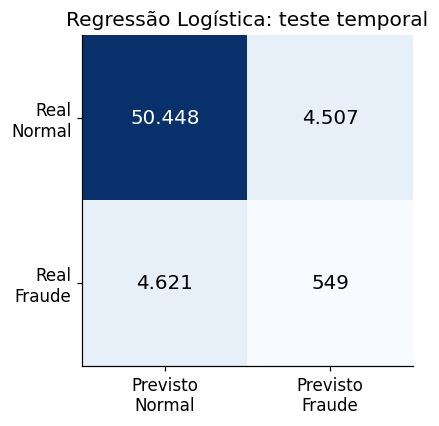

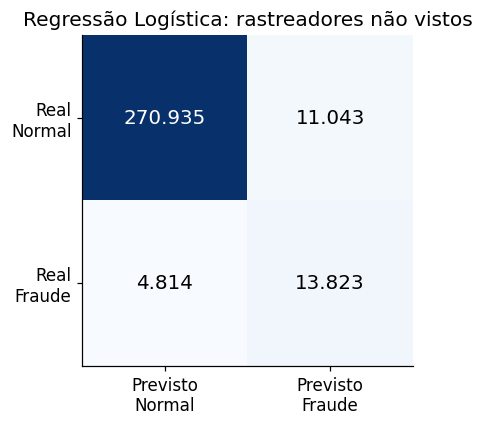

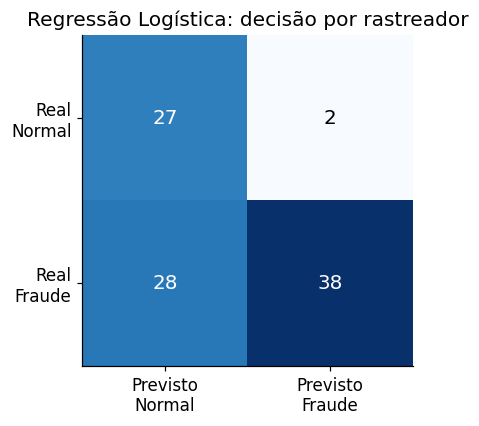

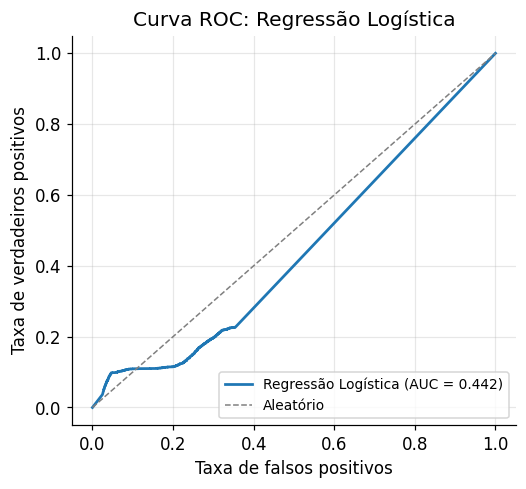

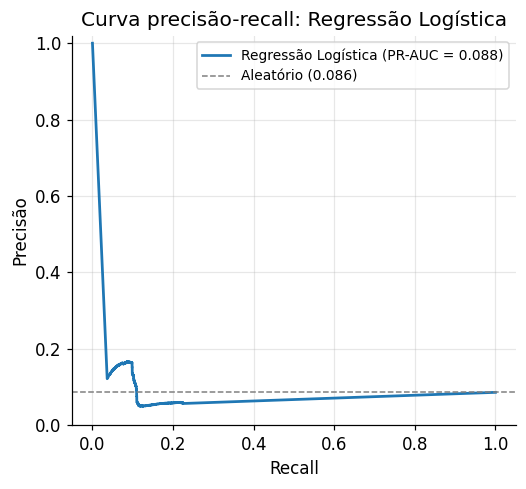

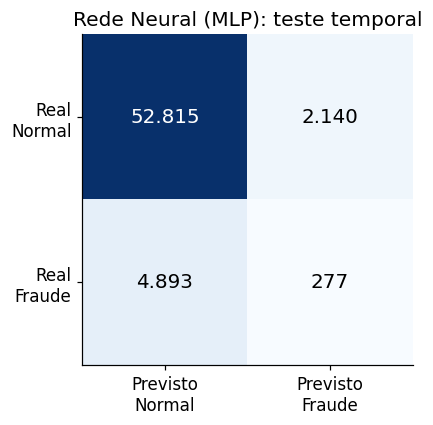

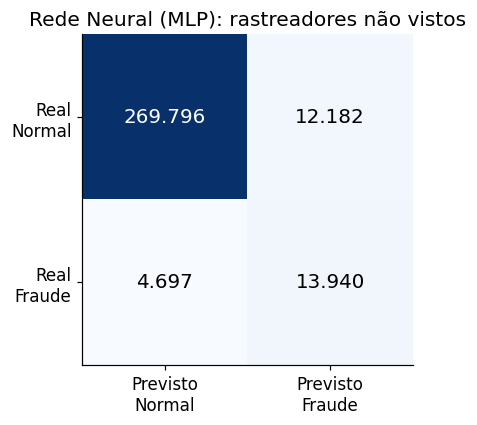

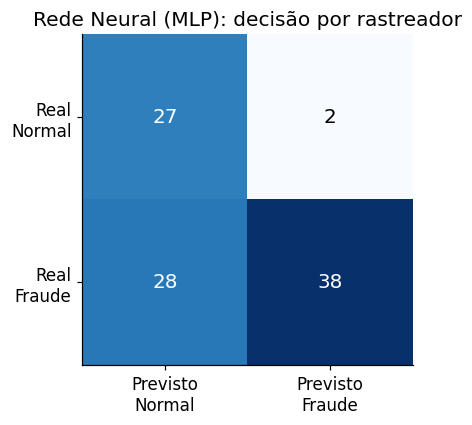

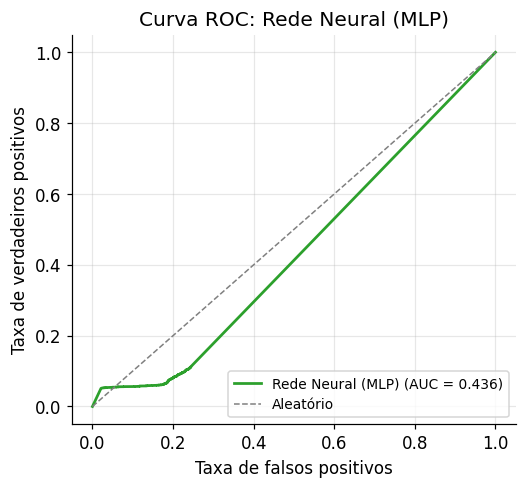

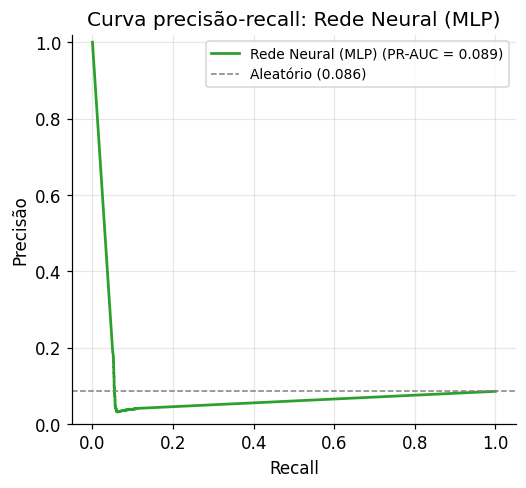

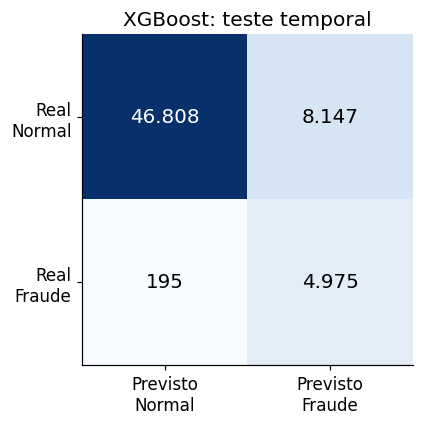

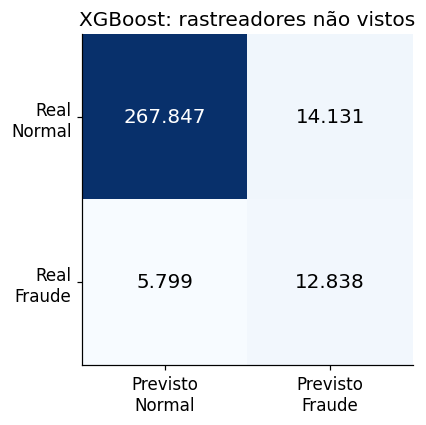

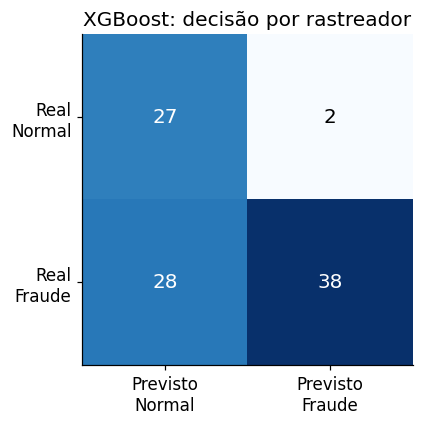

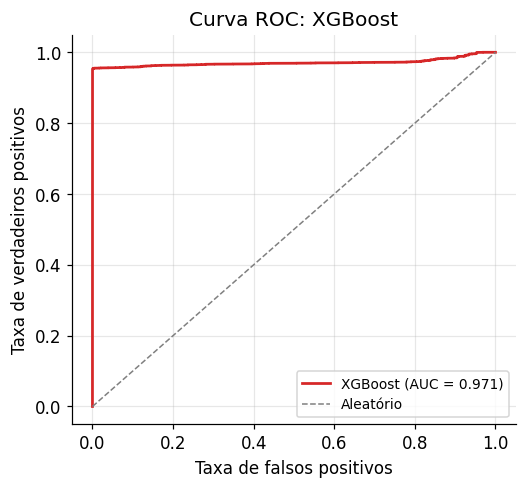

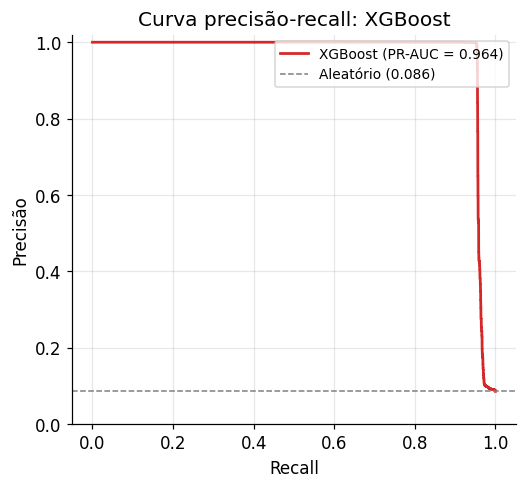

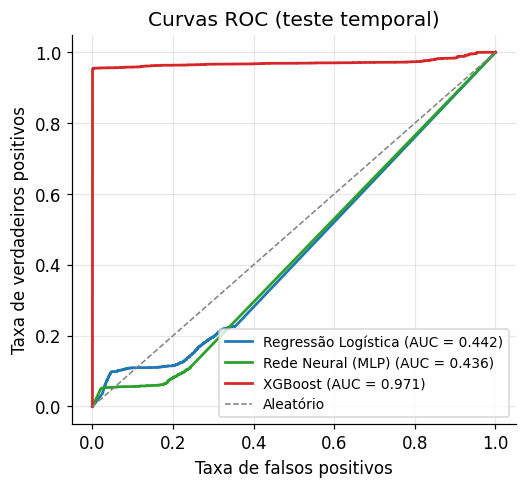

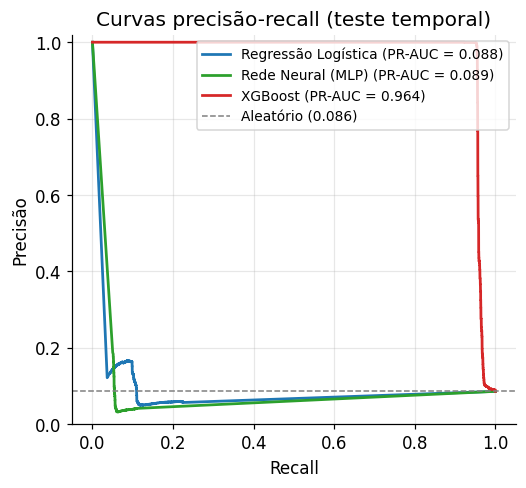

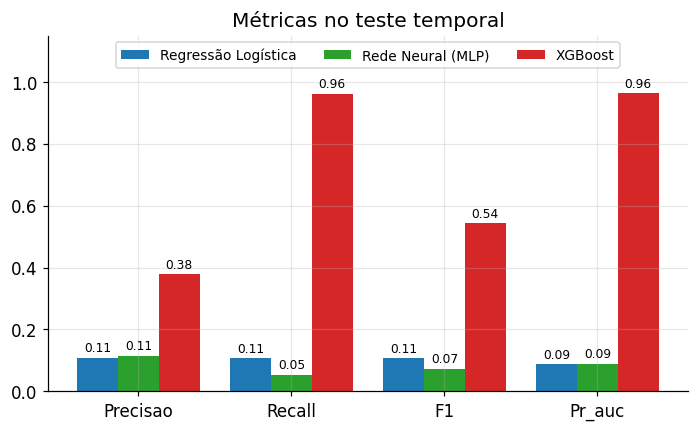

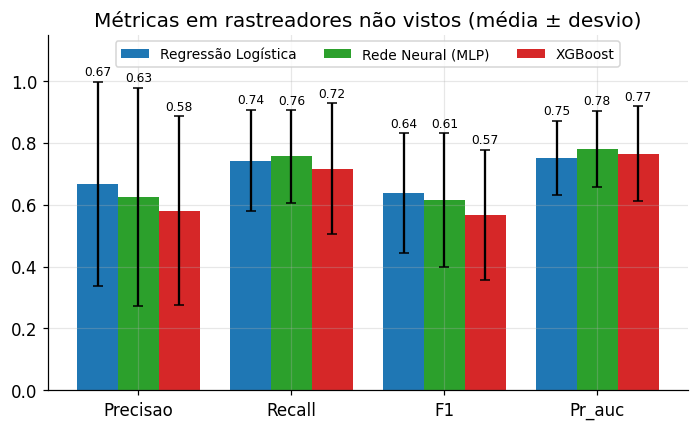

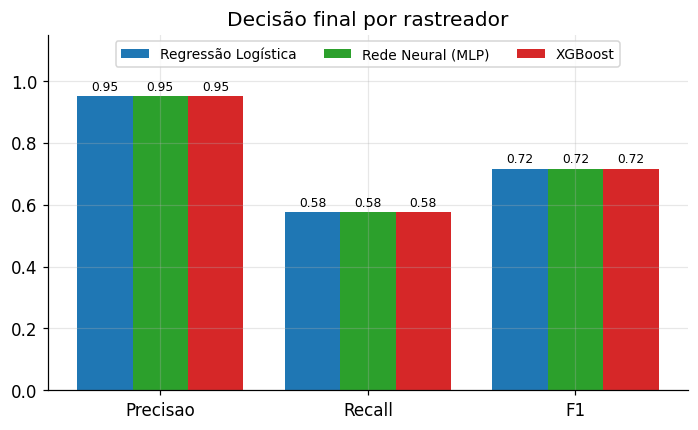

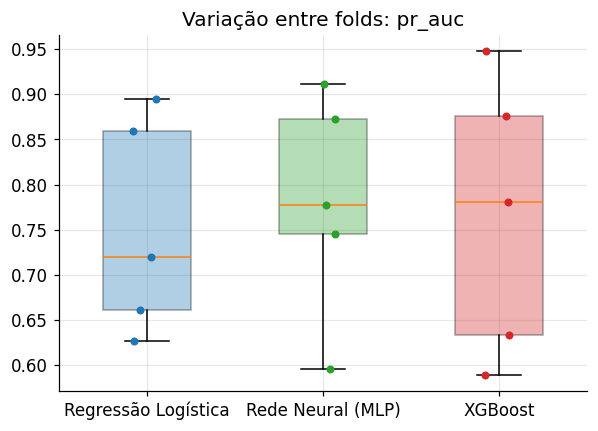

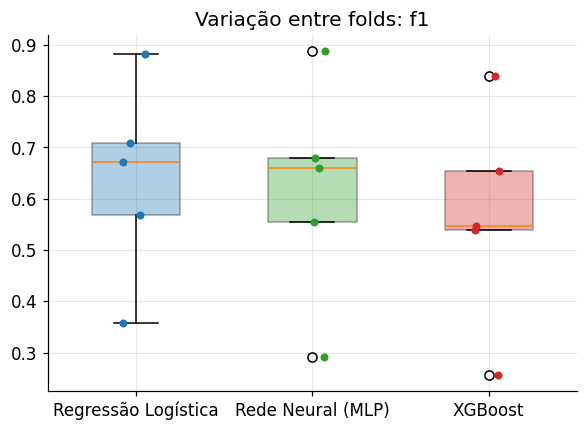

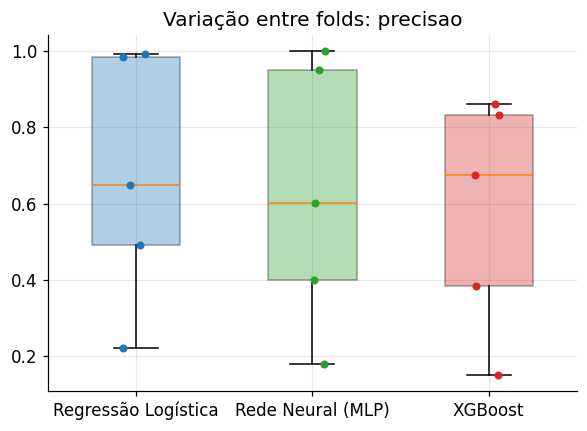

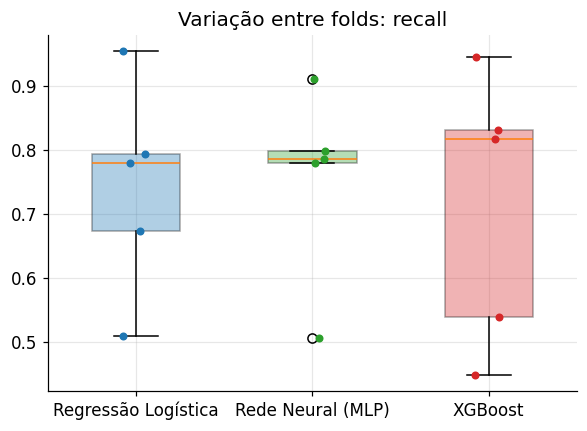

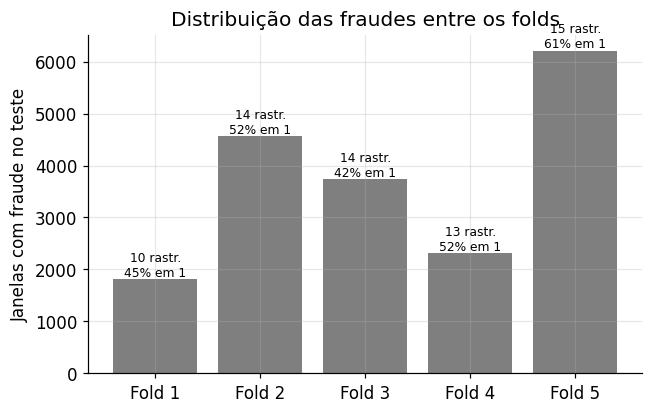

figuras salvas em /content/drive/MyDrive/dataset_tratado/resultados/figuras


In [13]:
for nome in MODELOS:
    s = SIGLA[nome]
    matriz_confusao(res_A.loc[nome], f"{nome}: teste temporal", DIR_FIG / f"{s}_matriz_temporal.png")
    soma = res_B[res_B["rep"] == 0].groupby("modelo")[["VP", "FN", "FP", "VN"]].sum().loc[nome]
    matriz_confusao(soma, f"{nome}: rastreadores não vistos", DIR_FIG / f"{s}_matriz_grupos.png")
    matriz_confusao(resumo_decisao.loc[nome], f"{nome}: decisão por rastreador",
                    DIR_FIG / f"{s}_matriz_rastreadores.png")
    curva_roc(y[te_A], {nome: prob_A[nome]}, f"Curva ROC: {nome}", DIR_FIG / f"{s}_roc.png")
    curva_pr(y[te_A], {nome: prob_A[nome]}, f"Curva precisão-recall: {nome}", DIR_FIG / f"{s}_pr.png")
    print("\n" * 3, flush=True)          # espaço entre os blocos de figuras de cada modelo

curva_roc(y[te_A], prob_A, "Curvas ROC (teste temporal)", DIR_FIG / "comparativo_roc.png")
print("\n" * 3, flush=True)
curva_pr(y[te_A], prob_A, "Curvas precisão-recall (teste temporal)", DIR_FIG / "comparativo_pr.png")
print("\n" * 3, flush=True)
barras(res_A, "Métricas no teste temporal", DIR_FIG / "comparativo_metricas_temporal.png")
print("\n" * 3, flush=True)
barras(media_B, "Métricas em rastreadores não vistos (média ± desvio)",
       DIR_FIG / "comparativo_metricas_grupos.png", desvio=desvio_B)
print("\n" * 3, flush=True)
barras(resumo_decisao, "Decisão final por rastreador",
       DIR_FIG / "comparativo_decisao_rastreadores.png", metricas_b=("precisao", "recall", "f1"))
for metrica in ["pr_auc", "f1", "precisao", "recall"]:
    boxplot(metrica, f"Variação entre folds: {metrica}", DIR_FIG / f"folds_{metrica}.png")
    print("\n" * 3, flush=True)

comp0 = composicao[composicao["rep"] == 0]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(np.arange(len(comp0)), comp0["janelas_fraude"], color="#7f7f7f")
for xi, (n, c) in enumerate(zip(comp0["com_fraude"], comp0["concentracao"])):
    ax.text(xi, comp0["janelas_fraude"].iloc[xi], f"{n} rastr.\n{c:.0%} em 1",
            ha="center", va="bottom", fontsize=8)
ax.set_xticks(np.arange(len(comp0)), [f"Fold {f + 1}" for f in comp0["fold"]])
ax.set_ylabel("Janelas com fraude no teste"); ax.set_title("Distribuição das fraudes entre os folds")
fig.savefig(DIR_FIG / "composicao_folds.png"); plt.show(); plt.close(fig)
print("figuras salvas em", DIR_FIG)

## 8. Modelos finais

Cada modelo é treinado com toda a base e salvo em resultados/modelos_finais.pkl, junto com as variáveis, os parâmetros e a regra de decisão usados no classificador.

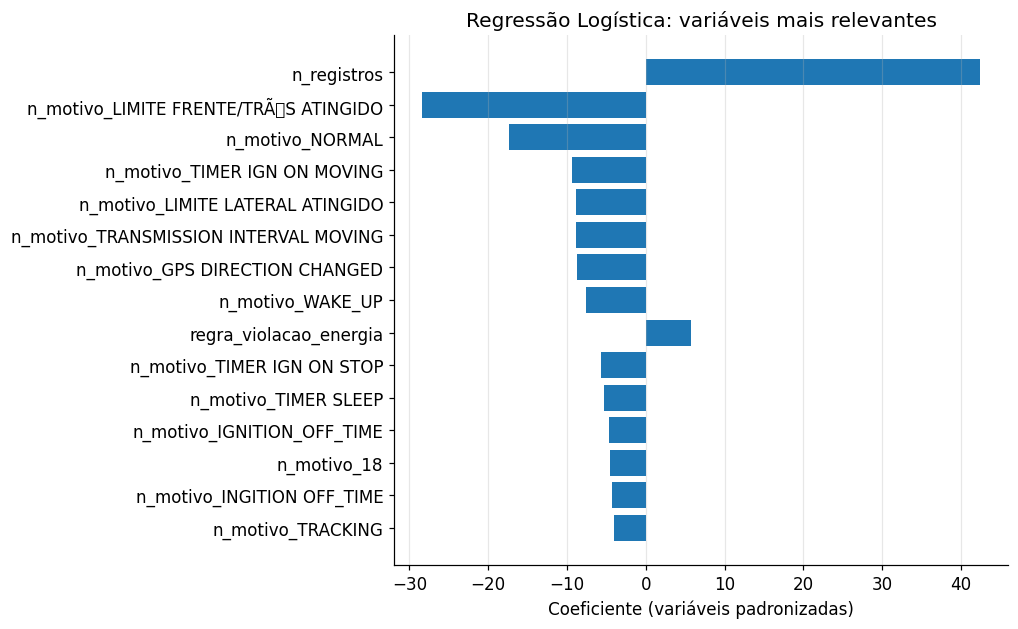

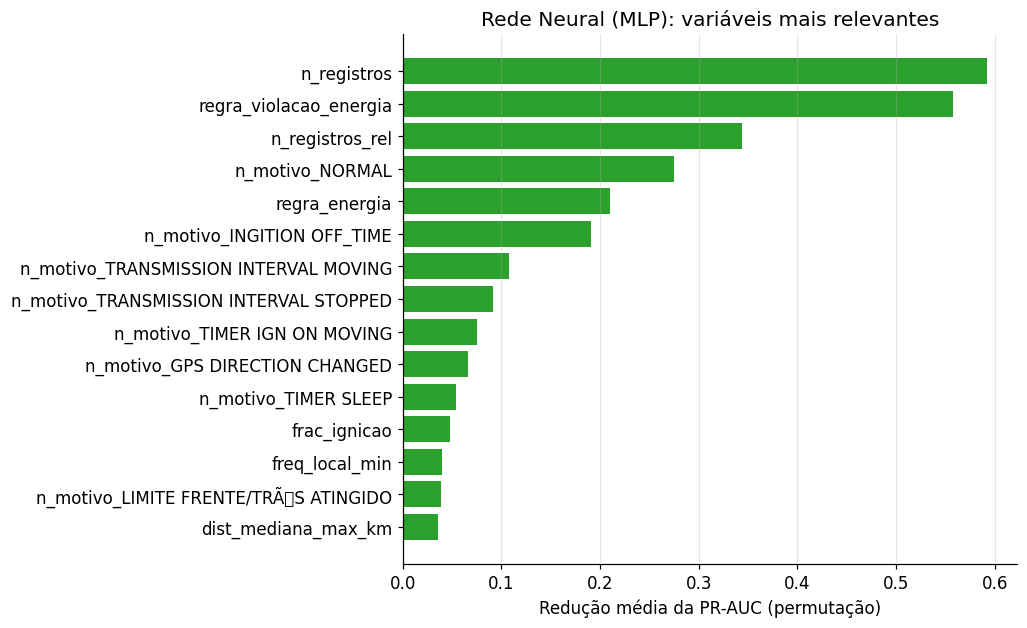

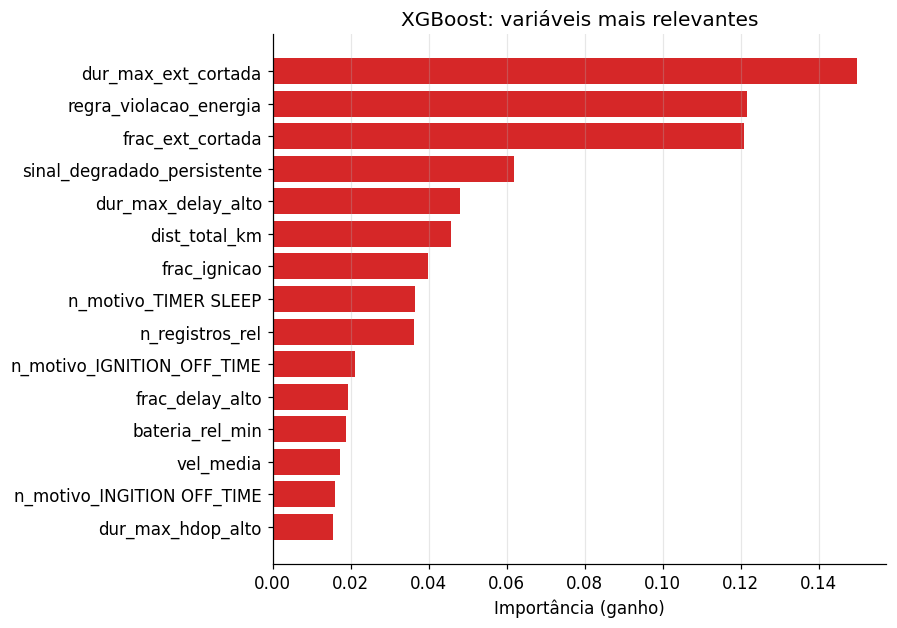

modelos salvos em /content/drive/MyDrive/dataset_tratado/resultados/modelos_finais.pkl


In [14]:
def importancia(nome, modelo, caminho, n=15):
    if nome == "Regressão Logística":
        v = pd.Series(modelo.named_steps["clf"].coef_[0], index=FEATURES)
        v = v.reindex(v.abs().sort_values().index).tail(n)
        eixo = "Coeficiente (variáveis padronizadas)"
    elif nome == "XGBoost":
        v = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values().tail(n)
        eixo = "Importância (ganho)"
    else:
        rng = np.random.default_rng(SEED)
        pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        amostra = np.concatenate([rng.choice(pos, min(len(pos), 3000), replace=False),
                                  rng.choice(neg, min(len(neg), 17000), replace=False)])
        r = permutation_importance(modelo, X[amostra], y[amostra], scoring="average_precision",
                                   n_repeats=3, random_state=SEED, n_jobs=1)
        v = pd.Series(r.importances_mean, index=FEATURES).sort_values().tail(n)
        eixo = "Redução média da PR-AUC (permutação)"
    fig, ax = plt.subplots(figsize=(7.2, 0.33 * len(v) + 1.3))
    ax.barh(v.index, v.to_numpy(), color=CORES[nome])
    ax.set_xlabel(eixo); ax.set_title(f"{nome}: variáveis mais relevantes")
    ax.grid(axis="y", alpha=0)
    fig.savefig(caminho); plt.show(); plt.close(fig)


idx_total = np.arange(len(y))
finais = {}
for nome in MODELOS:
    modelo = treinar(nome, idx_total)
    finais[nome] = {"modelo": modelo,
                    "limiar": float(res_B.loc[res_B["modelo"] == nome, "limiar"].median())}
    importancia(nome, modelo, DIR_FIG / f"{SIGLA[nome]}_importancia.png")

joblib.dump({"modelos": finais, "features": FEATURES, "params": PARAMS, "decisao": DECISAO},
            DIR_RESULT / "modelos_finais.pkl")
print("modelos salvos em", DIR_RESULT / "modelos_finais.pkl")

## 9. Tabela de métricas para a monografia

In [15]:
tabela = pd.concat({
    "Temporal": res_A[["precisao", "recall", "f1", "pr_auc", "roc_auc"]],
    "Entre rastreadores": media_B[["precisao", "recall", "f1", "pr_auc", "roc_auc"]],
    "Por rastreador": resumo_decisao[["precisao", "recall", "f1"]],
}, axis=1).round(3)
tabela.to_csv(DIR_RESULT / "tabela_metricas.csv", sep=";")
tabela

Temporal                              Entre rastreadores  \
                    precisao recall     f1 pr_auc roc_auc           precisao   
Regressão Logística    0.109  0.106  0.107  0.088   0.442              0.667   
Rede Neural (MLP)      0.115  0.054  0.073  0.089   0.436              0.626   
XGBoost                0.379  0.962  0.544  0.964   0.971              0.581   

                                                 Por rastreador                
                    recall     f1 pr_auc roc_auc       precisao recall     f1  
Regressão Logística  0.742  0.638  0.752   0.939           0.95  0.576  0.717  
Rede Neural (MLP)    0.756  0.615  0.780   0.915           0.95  0.576  0.717  
XGBoost              0.717  0.567  0.765   0.926           0.95  0.576  0.717

## 10. Classificador de um arquivo de rastreador

Recebe a planilha de auditoria de um rastreador, bruta ou já tratada, e devolve FRAUDE ou NÃO FRAUDE com risco e confiança de cada modelo.

In [16]:
def carregar(caminho):
    fp = Path(caminho)
    if fp.name.endswith("_treated.csv"):
        return pd.read_csv(fp, sep=";", low_memory=False)
    df, _ = tratar_arquivo(fp)
    return df


def analisar_arquivo(caminho, modelos=None):
    janelas = agregar_janelas(features_registro(carregar(caminho), PARAMS), PARAMS).reset_index(drop=True)
    Xj = janelas.reindex(columns=FEATURES)
    contagens = [c for c in FEATURES if c.startswith("n_motivo_")]
    Xj[contagens] = Xj[contagens].fillna(0)
    Xj = Xj.to_numpy(dtype=np.float32)
    Xj[~np.isfinite(Xj)] = np.nan

    resultados = {}
    for nome in modelos or MODELOS:
        prob = finais[nome]["modelo"].predict_proba(Xj)[:, 1]
        veredito, risco, episodios, _ = decisao_combinada(janelas, prob, PARAMS, DECISAO)
        resultados[nome] = {"veredito": veredito, "risco_pct": round(100 * risco, 1),
                            "confianca_pct": round(100 * (risco if veredito == "FRAUDE" else 1 - risco), 1),
                            "episodios_fraude": int(episodios["fraude"].sum()) if len(episodios) else 0,
                            "episodios_com_indicios": len(episodios), "episodios": episodios,
                            "prob": prob}
    votos = sum(r["veredito"] == "FRAUDE" for r in resultados.values())
    info = {"arquivo": Path(caminho).name, "rastreador": str(janelas["rastreador"].iloc[0]),
            "periodo": f"{janelas['inicio_janela'].min():%d/%m/%Y} a {janelas['inicio_janela'].max():%d/%m/%Y}",
            "consenso": "FRAUDE" if votos > len(resultados) / 2 else "NÃO FRAUDE",
            "votos": f"{votos} de {len(resultados)}"}
    return info, resultados, janelas


def resumo(resultados):
    return pd.DataFrame([{"modelo": n, "veredito": r["veredito"], "risco (%)": r["risco_pct"],
                          "confiança (%)": r["confianca_pct"],
                          "episódios de fraude": r["episodios_fraude"],
                          "episódios com indícios": r["episodios_com_indicios"]}
                         for n, r in resultados.items()])


def episodios(resultados, so_fraude=False):
    partes = [r["episodios"].assign(modelo=n) for n, r in resultados.items() if len(r["episodios"])]
    if not partes:
        return pd.DataFrame()
    ep = pd.concat(partes, ignore_index=True)
    if so_fraude:
        ep = ep[ep["fraude"]]
    ep = ep.sort_values(["fraude", "confianca"], ascending=False)
    ep["inicio"] = pd.to_datetime(ep["inicio"]).dt.strftime("%d/%m/%Y %H:%M")
    ep["fim"] = pd.to_datetime(ep["fim"]).dt.strftime("%d/%m/%Y %H:%M")
    ep["confianca"] = (100 * ep["confianca"].astype(float)).round(1)
    ep["fraude"] = ep["fraude"].map({True: "sim", False: "não"})
    return ep[["modelo", "fraude", "confianca", "inicio", "fim", "duracao_h",
               "n_indicios", "indicios", "lat", "lng"]].reset_index(drop=True)


def grafico_risco(janelas, resultados, caminho=None):
    fig, eixos = plt.subplots(len(resultados), 1, figsize=(13, 2.4 * len(resultados) + 0.8),
                              sharex=True, squeeze=False)
    for ax, (nome, r) in zip(eixos[:, 0], resultados.items()):
        ax.plot(janelas["inicio_janela"], r["prob"], lw=0.7, color=CORES[nome])
        for _, e in r["episodios"].iterrows():
            ax.axvspan(e["inicio"], e["fim"], lw=0, color="red" if e["fraude"] else "orange",
                       alpha=0.25 if e["fraude"] else 0.12)
        ax.axhline(DECISAO["RISCO_MIN"], color="red", ls="--", lw=0.8)
        ax.set_ylim(-0.02, 1.02); ax.set_ylabel("Risco")
        ax.set_title(f"{nome}: {r['veredito']} (risco {r['risco_pct']:.1f}%)", loc="left", fontsize=10)
    fig.tight_layout()
    if caminho:
        fig.savefig(caminho)
    plt.show(); plt.close(fig)

69251992613cd7d158638cb9_auditoria.csv | 22/06/2021 a 20/07/2021 | consenso: FRAUDE (3 de 3 modelos)


,modelo,veredito,risco (%),confiança (%),episódios de fraude,episódios com indícios
0,Regressão Logística,FRAUDE,100.0,100.0,22,30
1,Rede Neural (MLP),FRAUDE,100.0,100.0,14,30
2,XGBoost,FRAUDE,100.0,100.0,24,30


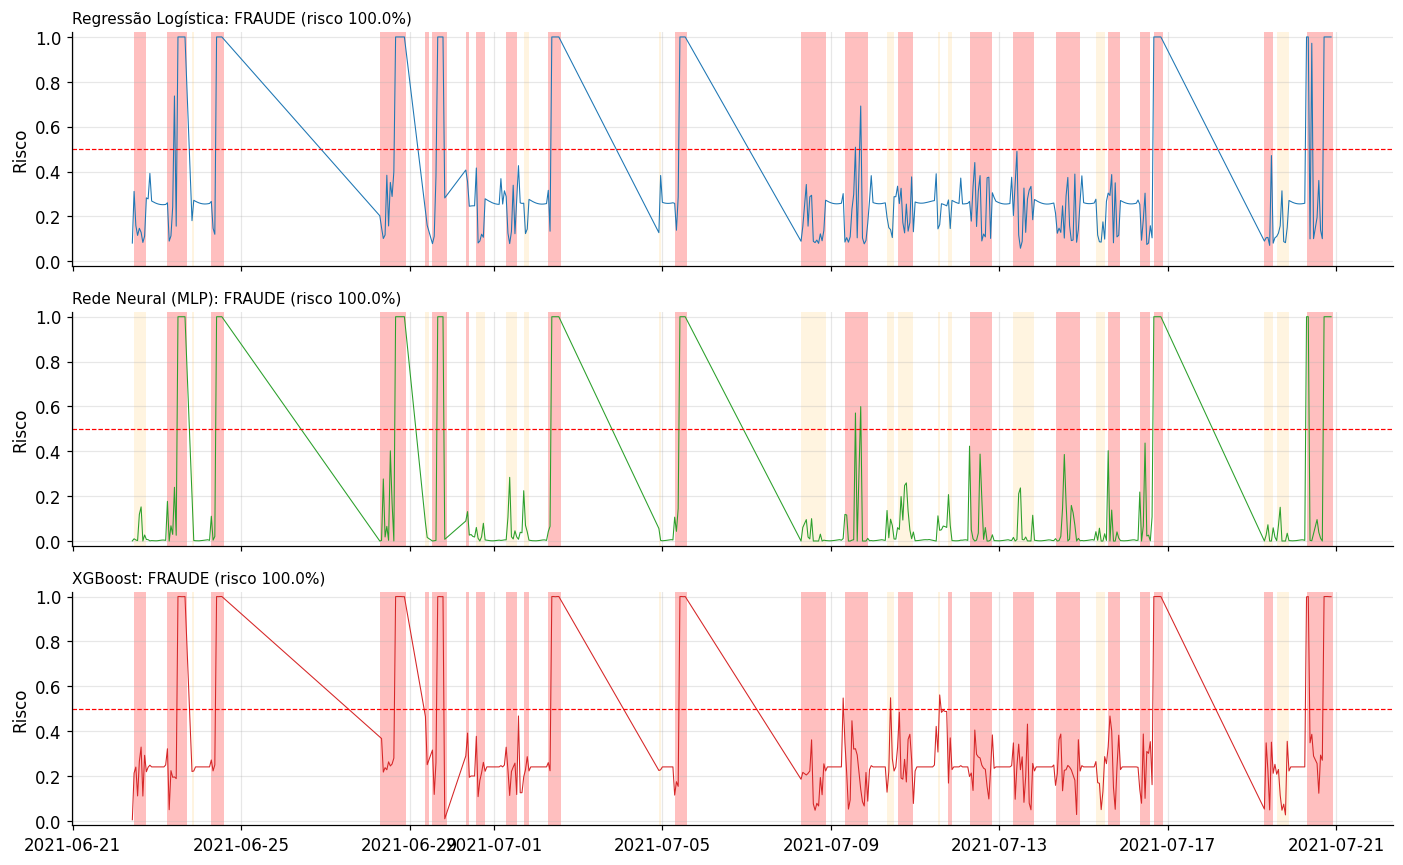

,modelo,fraude,confianca,inicio,fim,duracao_h,n_indicios,indicios,lat,lng
0,Regressão Logística,sim,100.0,23/06/2021 06:00,23/06/2021 17:00,11.0,4,energia externa cortada / falha ou tensão baix...,-22.782012,-43.124602
1,Regressão Logística,sim,100.0,24/06/2021 07:00,24/06/2021 14:00,7.0,4,energia externa cortada / falha ou tensão baix...,-22.815341,-43.105993
2,Regressão Logística,sim,100.0,28/06/2021 07:00,28/06/2021 22:00,15.0,4,energia externa cortada / falha ou tensão baix...,-22.863364,-43.106455
3,Regressão Logística,sim,100.0,05/07/2021 07:00,05/07/2021 14:00,7.0,4,energia externa cortada / falha ou tensão baix...,-22.748612,-43.173121
4,Regressão Logística,sim,100.0,02/07/2021 07:00,02/07/2021 14:00,7.0,4,energia externa cortada / falha ou tensão baix...,-22.555969,-43.175388
5,Regressão Logística,sim,100.0,29/06/2021 13:00,29/06/2021 21:00,8.0,4,energia externa cortada / falha ou tensão baix...,-22.836914,-43.026516
6,Regressão Logística,sim,100.0,20/07/2021 07:00,20/07/2021 22:00,15.0,4,energia externa cortada / falha ou tensão baix...,-22.647851,-43.158498
7,Regressão Logística,sim,100.0,16/07/2021 16:00,16/07/2021 21:00,5.0,4,energia externa cortada / falha ou tensão baix...,-22.728483,-42.833195
8,Rede Neural (MLP),sim,100.0,23/06/2021 06:00,23/06/2021 17:00,11.0,4,energia externa cortada / falha ou tensão baix...,-22.782012,-43.124602
9,Rede Neural (MLP),sim,100.0,24/06/2021 07:00,24/06/2021 14:00,7.0,4,energia externa cortada / falha ou tensão baix...,-22.815341,-43.105993


In [17]:
ARQUIVO = DIR_BRUTOS / "69251992613cd7d158638cb9_auditoria.csv"   # arquivo do rastreador a analisar

info, resultados, janelas = analisar_arquivo(ARQUIVO)
print(f"{info['arquivo']} | {info['periodo']} | consenso: {info['consenso']} ({info['votos']} modelos)")
display(resumo(resultados))
grafico_risco(janelas, resultados, DIR_FIG / f"risco_{Path(ARQUIVO).stem}.png")
episodios(resultados, so_fraude=True).head(20)

### Analisar um arquivo enviado do computador

Saving 65c4c75f8cc6500f47d36bc1_auditoria.csv to 65c4c75f8cc6500f47d36bc1_auditoria.csv
65c4c75f8cc6500f47d36bc1_auditoria.csv: FRAUDE (3 de 3 modelos)


,modelo,veredito,risco (%),confiança (%),episódios de fraude,episódios com indícios
0,Regressão Logística,FRAUDE,80.1,80.1,13,48
1,Rede Neural (MLP),FRAUDE,99.3,99.3,4,48
2,XGBoost,FRAUDE,86.6,86.6,14,48


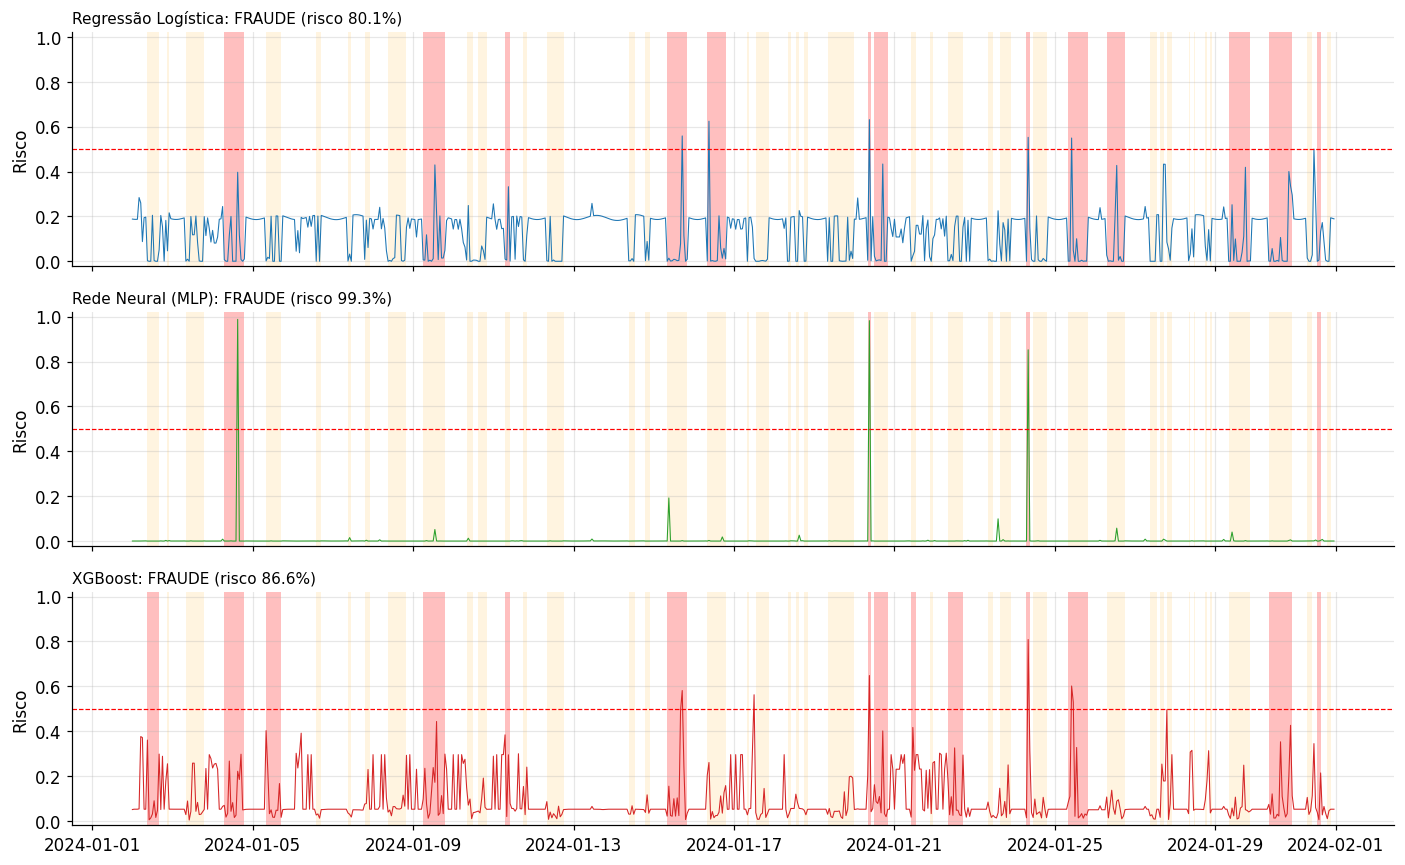

In [20]:
from google.colab import files

for nome_enviado in files.upload():
    info, resultados, janelas = analisar_arquivo(nome_enviado)
    print(f"{info['arquivo']}: {info['consenso']} ({info['votos']} modelos)")
    display(resumo(resultados))
    grafico_risco(janelas, resultados)

## 11. Ranking de uma pasta

In [ ]:
linhas = []
for fp in sorted(DIR_BRUTOS.glob("*_auditoria.csv")):
    try:
        info, resultados, _ = analisar_arquivo(fp)
    except Exception as e:
        print(f"{fp.name}: {type(e).__name__}: {e}")
        continue
    linha = {"arquivo": info["arquivo"], "periodo": info["periodo"], "consenso": info["consenso"]}
    for nome, r in resultados.items():
        linha[f"{nome} - veredito"] = r["veredito"]
        linha[f"{nome} - risco (%)"] = r["risco_pct"]
    linhas.append(linha)

ranking = pd.DataFrame(linhas)
colunas_risco = [c for c in ranking.columns if c.endswith("risco (%)")]
ranking["risco medio (%)"] = ranking[colunas_risco].mean(axis=1).round(1)
ranking = ranking.sort_values("risco medio (%)", ascending=False)
ranking.to_csv(DIR_RESULT / "ranking_rastreadores.csv", sep=";", index=False)
print(ranking["consenso"].value_counts())
ranking.head(30)